# Finding planets in TESS data: the `tls_masked_search` pipeline, chapter by chapter

Some stars get slightly dimmer for a few hours, again and again, at regular times. Sometimes that is a planet passing in front of the star. Often it is something else (a *fake*). This pipeline finds those repeating dips and gives each one a score from 0 (fake) to 1 (planet).

This notebook follows real stars through every step, with a picture for every idea. It was started by Mika (chapters 2-4) and extended by Abdullah (the models and the newer chapters).

## How to read this

- Read the text and the pictures; the code cells can be skipped. Each chapter builds on the one before.
- Every number comes from the pipeline's committed files (`tls_masked_search/output/`) or is recomputed here. A few numbers that can't be recomputed on a laptop (they need a GPU or deleted downloads) are quoted and marked **(from the README)**.
- `assert` lines are checks: if a claim in the text stopped being true, the notebook would stop with an error there.

A few words used throughout:

| word | meaning |
|---|---|
| TESS | NASA's planet-hunting space telescope |
| TIC number | a star's ID in the TESS star catalogue |
| sector | one ~27-day stretch of TESS observing ("a month of data") |
| light curve | a star's brightness over time |
| dip / signal | a repeating drop in brightness that our search found |
| TOI | a dip NASA has listed as worth checking ("TESS Object of Interest") |
| ppm | parts per million: 10,000 ppm = 1% dimmer |

## Chapters

1. [The data](#ch1)
2. [One star, start to finish](#ch2)
3. [Is it a known planet?](#ch3)
4. [Labels: NASA's verdicts become training answers](#ch4)
5. [The 12 measurements](#ch5)
6. [The snapshots: six pictures of the dip](#ch6)
7. [The models, and how we grade them](#ch7)
8. [Pixel images: which star dimmed?](#ch8)
9. ["Nothing here" stars](#ch9)
10. [The "unsure" flag](#ch10)
11. [The wrong-star fix](#ch11)
12. [Tried and dropped](#ch12)
13. [Recap and what's next](#ch13)

In [1]:
import importlib, json, os, sys, time, warnings
for var in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMBA_NUM_THREADS']:
    os.environ.setdefault(var, '8')   # keep maths libraries from spreading over every core of a shared machine
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import lightkurve as lk
import torch
from astropy.io import fits
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from IPython.display import display

START = time.time()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tls_masked_search/common.py').exists())
sys.path[:0] = [str(ROOT / 'tls_masked_search'), str(ROOT)]
import common
from common import OUT_DIR, clean_and_stitch
from tess_hunt.photometry import preprocess, robust_sigma
from tess_hunt.search import phase_offset, vet_signal, weighted_mean
m2 = importlib.import_module('02_build_dataset')      # search, the 12 measurements
m3 = importlib.import_module('03_train_trees')        # labels, trees, grading helpers
m4 = importlib.import_module('04_build_snapshots')    # the 6 snapshots
m6 = importlib.import_module('06_train_shape_model')  # the shape model (network)
torch.set_num_threads(8)  # this tiny network runs slower when spread over every core of a big machine

%matplotlib inline
plt.rcParams.update({'figure.dpi': 72, 'axes.grid': True, 'grid.alpha': .2, 'axes.formatter.useoffset': False,
                     'axes.spines.top': False, 'axes.spines.right': False})
PAL = ['#2269a8', '#d6791a', '#25866e', '#a44265']
CONFIG = json.loads((ROOT / 'config/benchmark.json').read_text())

# Committed tables, loaded once.
targets = pd.read_csv(ROOT / 'data/benchmark/targets.csv')                # the 100 benchmark stars
bench = pd.read_csv(OUT_DIR / 'benchmark_100.csv')                       # our search on them
bench_hosts = pd.read_csv(OUT_DIR / 'benchmark_100_hosts.csv')
SETS = ['dataset', 'dataset_v2', 'candidates']
stars = {n: pd.read_csv(OUT_DIR / f'{n}_stars.csv') for n in SETS}       # one row per star
signals = {n: pd.read_csv(OUT_DIR / f'{n}_signals.csv') for n in SETS}   # one row per dip found
shape_scores = pd.read_csv(OUT_DIR / 'shape_scores.csv')                 # stored model scores (unseen stars)
ranking = pd.read_csv(OUT_DIR / 'candidate_ranking.csv')                 # the final ranked list
npz = np.load(OUT_DIR / 'views.npz')                                     # the 6 snapshots per dip
pix = np.load(OUT_DIR / 'dataset_pixel_views.npz')                       # the pixel images per dip
PIX_META = json.loads(str(pix['meta']))

# One row per labelled dip (NASA planet: y = 1, NASA fake: y = 0), with the stored model scores.
df = m3.load().reset_index(drop=True)
df = df.merge(shape_scores[['tic', 'signal', 'gbt', 'views', 'views_features', 'shape_score_spread', 'fold']],
              on=['tic', 'signal'])
assert len(df) == len(shape_scores) and df.hard.all()   # stored scores cover exactly these dips, all NASA-labelled
df['view_row'] = m6.rows_of(npz, df)
df['views_ok'] = npz['ok'][df.view_row]
df['pix_row'] = m6.rows_of(pix, df)
hard = df[df.views_ok]                                  # dips whose snapshots could be built

PLAIN = {   # the 12 measurements, in plain words
    'period': 'time between dips (days)',
    'duration_h': 'dip length (hours)',
    'depth_ppm': 'dip depth (parts per million)',
    'sde_per_transit': 'search peak height (per dip)',
    'depth_snr_per_transit': 'stands out from noise (per dip)',
    'pink_snr_per_transit': 'stands out from slow, wavy noise (per dip)',
    'odd_even_sigma': 'odd/even depth difference',
    'secondary_snr': 'halfway dip strength',
    'centroid_snr': 'star position shift',
    'transits_per_sector': 'dips seen per month',
    'significant_event_fraction': 'share of dips clear on their own',
    'chunk_fraction': 'share of data blocks that found it',
}
assert list(PLAIN) == m3.DIP_FEATURES
VERDICT = {'CP': 'confirmed planet', 'KP': 'known planet', 'FP': 'fake', 'FA': 'fake'}
EX = {'A': 273874849, 'B': 96291218, 'C': 279999655, 'D': 349790953}   # example stars, raw files kept locally
ex = {k: df[(df.tic == tic) & (df.signal == 1)].iloc[0] for k, tic in EX.items()}
COLORS = {'A': 'tab:green', 'B': 'tab:orange', 'C': 'tab:red', 'D': 'tab:purple'}
paths = {k: m4.capped(sorted(str(p) for p in m4.RAW.glob(f'*{tic:016d}*'))) for k, tic in EX.items()}


def flow(ax, labels, y=0.5, h=0.6, fc='#e8f0fa'):
    # Draw labelled boxes left to right, joined by arrows.
    for i, lab in enumerate(labels):
        ax.add_patch(FancyBboxPatch((i + 0.06, y - h / 2), 0.88, h, boxstyle='round,pad=0.02', fc=fc, ec='0.4'))
        ax.text(i + 0.5, y, lab, ha='center', va='center', fontsize=9)
        if i < len(labels) - 1:
            ax.annotate('', xy=(i + 1.05, y), xytext=(i + 0.95, y), arrowprops=dict(arrowstyle='->', lw=1.5))
    ax.set_xlim(0, len(labels)); ax.axis('off')

print(f'{len(df)} NASA-labelled dips: {df.y.sum()} planets, {(df.y == 0).sum()} fakes')

load: dropped 18 rows ({'FP': 13, 'FA': 4, 'KP': 1}) of 18 stars with no light curve of their own
1725 NASA-labelled dips: 1111 planets, 614 fakes


## The whole pipeline on one page

1. **Download**: TESS measures each star's brightness every 2 minutes, a sector (month) at a time.
2. **Clean**: remove slow brightness drifts and bad points.
3. **Search**: try thousands of possible periods (time between dips) and find the one where dips line up best. The tool is **TLS** (Transit Least Squares).
4. **Search again**: hide the dips just found and search once more, to catch a second, weaker signal.
5. **Describe each dip**: (a) **6 snapshots** (pictures of the dip shape); (b) **12 measurements** (numbers); (c) **pixel images** (which star on the camera dimmed).
6. **Model**: a small neural network reads all three and gives a score from 0 to 1.
7. **Ranked list**: sort NASA's undecided dips by score; the top ones are the best candidates to check by hand.

NASA's verdicts (planet / fake) are used **only** to train and grade the model, never as an input.

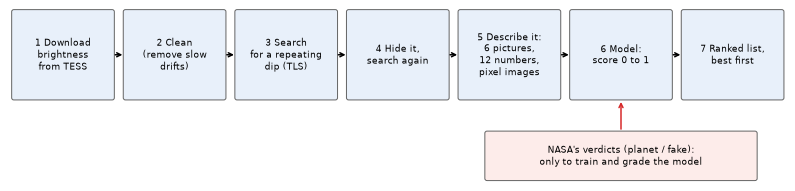

In [2]:
fig, ax = plt.subplots(figsize=(14, 3.2))
flow(ax, ['1 Download\nbrightness\nfrom TESS', '2 Clean\n(remove slow\ndrifts)', '3 Search\nfor a repeating\ndip (TLS)',
          '4 Hide it,\nsearch again', '5 Describe it:\n6 pictures,\n12 numbers,\npixel images', '6 Model:\nscore 0 to 1',
          '7 Ranked list,\nbest first'], y=1.2, h=0.8)
ax.add_patch(FancyBboxPatch((4.3, 0.05), 2.4, 0.42, boxstyle='round,pad=0.02', fc='#fdecea', ec='0.4'))
ax.text(5.5, 0.26, "NASA's verdicts (planet / fake):\nonly to train and grade the model", ha='center', va='center', fontsize=9)
ax.annotate('', xy=(5.5, 0.78), xytext=(5.5, 0.49), arrowprops=dict(arrowstyle='->', lw=1.5, color='tab:red'))
ax.set_ylim(0, 1.65)
plt.show()

<a id="ch1"></a>
# Chapter 1: The data

**What you'll learn:** what TESS records, and which sets of stars this project uses (and how big each one is).

TESS photographs a strip of sky for about 27 days (one **sector**), then moves on. For a few thousand chosen stars per sector it keeps a brightness measurement every 2 minutes: that star's **light curve**. Many stars are seen in several sectors.

We use four sets of stars, all with 2-minute light curves:

| set | what it's for |
|---|---|
| benchmark | 100 stars (60 with known planets, 40 without), one sector each: does the search find known planets? |
| dataset | stars with NASA-checked dips (planets and fakes), up to 8 sectors each: trains and grades the models |
| dataset_v2 | the same idea with up to 16 sectors, plus 1,000 random stars with no TOI ("nothing here", chapter 9) |
| candidates | stars with dips NASA hasn't decided on yet: what we rank at the end |

,benchmark,dataset,dataset_v2,candidates
stars,100.0,2454,3454,5143
stars with their own 2-min data,100.0,2186,3184,4316
months (sectors) of data used,100.0,7435,15732,14027
dips found,83.0,5554,8199,10894
dips with a NASA planet/fake verdict,NaN,1743,1764,2


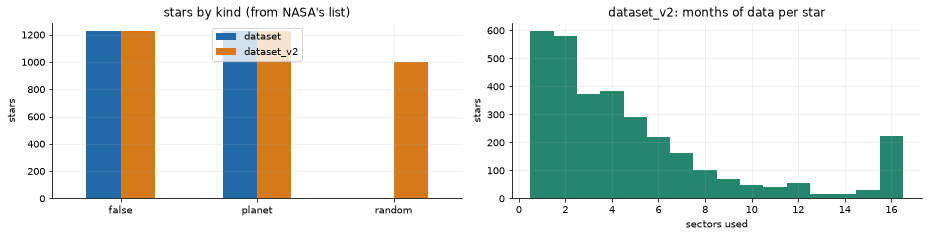

In [3]:
def summary(name):
    s, g = stars[name], signals[name]
    own = s.has_own_lc.astype(bool)
    labelled = g.label.isin(['CP', 'KP', 'FP', 'FA'])
    return {'stars': len(s), 'stars with their own 2-min data': int((s.sectors.fillna(0).gt(0) & own).sum()),
            'months (sectors) of data used': int(s.sectors.fillna(0).sum()), 'dips found': len(g),
            'dips with a NASA planet/fake verdict': int(labelled.sum())}

census = pd.DataFrame({'benchmark': {'stars': len(targets), 'stars with their own 2-min data': len(targets),
                                     'months (sectors) of data used': len(targets),
                                     'dips found': int(bench.sde.ge(common.MIN_SDE).sum() + bench.s2_sde.ge(common.MIN_SDE).sum()),
                                     'dips with a NASA planet/fake verdict': np.nan},
                       **{n: summary(n) for n in SETS}})
display(census)
assert len(targets) == 100

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
classes = pd.DataFrame({n: stars[n].star_class.value_counts() for n in ['dataset', 'dataset_v2']}).fillna(0)
classes.plot.bar(ax=axes[0], color=PAL[:2], rot=0)
axes[0].legend(loc='upper center')
axes[0].set(title='stars by kind (from NASA\'s list)', ylabel='stars', xlabel='')
s2 = stars['dataset_v2']
axes[1].hist(s2.sectors.dropna(), np.arange(0.5, 17.5), color=PAL[2])
axes[1].set(title='dataset_v2: months of data per star', xlabel='sectors used', ylabel='stars')
plt.tight_layout(); plt.show()

"planet" stars host a NASA-confirmed planet; "false" stars only have dips NASA called fake; "random" stars have no TOI at all. Many stars are watched for months; that matters later (chapter 5: more data makes any dip look stronger).

<a id="ch2"></a>
# Chapter 2: One star, start to finish

**What you'll learn:** how one star's raw brightness becomes a list of repeating dips: cleaning, searching, refining, searching again, and checking each dip. We follow **TOI-880** (TIC 34077285), a benchmark star with known planets.

TOI-880, sector 107: 20,656 measurements, 18,729 after dropping flagged ones


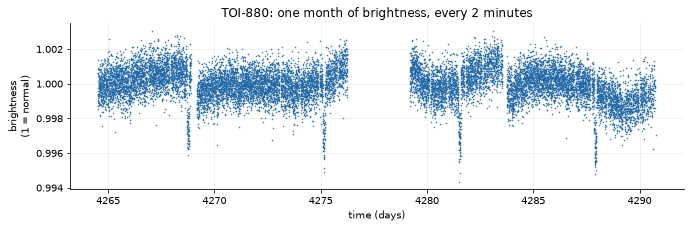

In [4]:
TIC = 34077285
target = targets.set_index('tic').loc[TIC]
path = ROOT / 'data/raw/benchmark' / target['filename']
assert path.exists(), 'TOI-880 light curve missing: run python scripts/run_benchmark.py download'
with fits.open(path) as hdul:
    n_rows = len(hdul[1].data)
lc = lk.read(path, flux_column='pdcsap_flux')     # also drops measurements TESS flagged as bad
print(f"{target['hostname']}, sector {target['sector']}: {n_rows:,} measurements, {len(lc):,} after dropping flagged ones")

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(lc.time.value, lc.flux.value / np.nanmedian(lc.flux.value), '.', ms=1, color=PAL[0])
ax.set(xlabel='time (days)', ylabel='brightness\n(1 = normal)', title='TOI-880: one month of brightness, every 2 minutes')
plt.show()

## Cleaning

The brightness drifts slowly (the star's spots, the telescope warming up). A dip from a planet lasts only hours. So we fit a smooth curve over about 33 hours, divide it out, remove upward spikes, and average into 10-minute points.

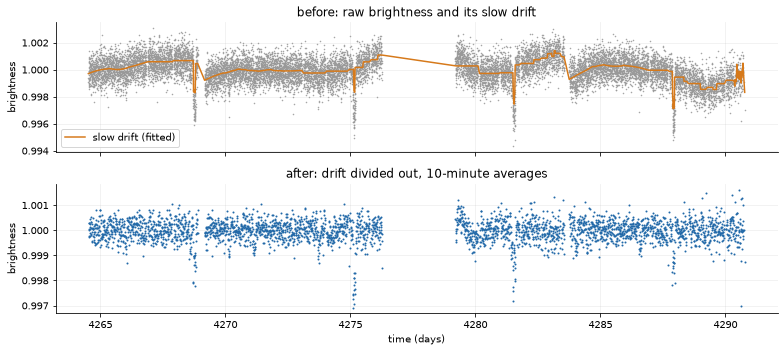

In [5]:
normalized = lc.remove_nans().normalize()
_, trend = normalized.flatten(window_length=1001, return_trend=True)   # the pipeline's smoothing (1001 points = 33 h)
t, y, dy = clean_and_stitch([lc], CONFIG['bin_minutes'])              # the pipeline's whole cleaning recipe

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(normalized.time.value, normalized.flux.value, '.', ms=1, color='0.6')
axes[0].plot(trend.time.value, trend.flux.value, color=PAL[1], lw=1.5, label='slow drift (fitted)')
axes[0].set(ylabel='brightness', title='before: raw brightness and its slow drift'); axes[0].legend()
axes[1].plot(t, y, '.', ms=2, color=PAL[0])
axes[1].set(xlabel='time (days)', ylabel='brightness', title='after: drift divided out, 10-minute averages')
plt.tight_layout(); plt.show()

## The search (TLS)

TLS tries thousands of periods (0.5 to 12 days here). For each it asks: "if a planet-shaped dip repeated this often, how well would it fit?" The answer is a strength per period. A real repeating dip gives one tall, sharp peak. The peak's height is the **SDE** ("how many typical wiggles above average"); we require **SDE ≥ 7**.

`common.two_pass` does the whole search in one call: a wide search, then the refinement shown in the next cell.

search took 2 s: best period 6.3909 days, SDE 17.6


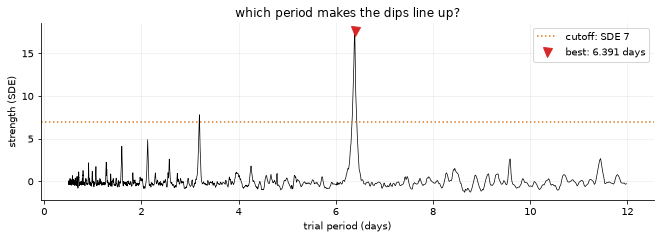

In [6]:
star = {**common.star_kwargs(float(target['mass']), float(target['radius'])), 'use_threads': 8}
t0 = time.time()
wide1, fine1 = common.two_pass(lc, star, CONFIG)
print(f'search took {time.time() - t0:.0f} s: best period {wide1.period:.4f} days, SDE {wide1.SDE:.1f}')
assert wide1.SDE >= common.MIN_SDE and fine1 is not None

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(wide1.periods, wide1.power, color='k', lw=.7)
ax.axhline(common.MIN_SDE, color=PAL[1], ls=':', label='cutoff: SDE 7')
ax.plot(wide1.period, wide1.SDE, 'v', color='tab:red', ms=9, label=f'best: {wide1.period:.3f} days')
ax.set(xlabel='trial period (days)', ylabel='strength (SDE)', title='which period makes the dips line up?')
ax.legend(); plt.show()

## Refine: clean again with the dips hidden

The smoothing curve can sag into a dip and swallow part of it. Now that we know when the dips are, we refit the smoothing with those times hidden, then run a fine search within ±0.5% of the period. The dip comes out deeper and better measured.

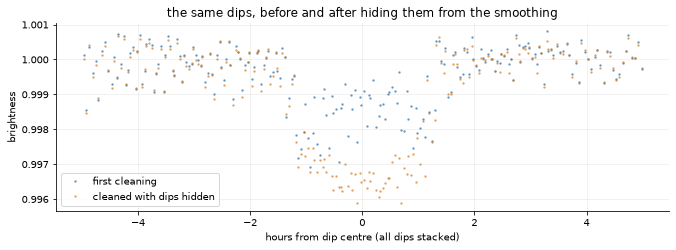

,wide search,refined
period (days),6.3909,6.3872
depth (ppm),1610.2431,3295.4370
dip length (hours),2.9318,2.7590


In [7]:
tm, ym, dym = clean_and_stitch([lc], CONFIG['bin_minutes'], ephemeris=(wide1.period, wide1.T0, wide1.duration))
fig, ax = plt.subplots(figsize=(11, 3.4))
for tt, ff, label, color in [(t, y, 'first cleaning', PAL[0]), (tm, ym, 'cleaned with dips hidden', PAL[1])]:
    h = phase_offset(tt, wide1.period, wide1.T0) * 24
    near = np.abs(h) < 5
    ax.plot(h[near], ff[near], '.', ms=3, alpha=.5, color=color, label=label)
ax.set(xlabel='hours from dip centre (all dips stacked)', ylabel='brightness', title='the same dips, before and after hiding them from the smoothing')
ax.legend(); plt.show()
fit_table = pd.DataFrame({'wide search': [wide1.period, (1 - wide1.depth) * 1e6, wide1.duration * 24],
                          'refined': [fine1.period, (1 - fine1.depth) * 1e6, fine1.duration * 24]},
                         index=['period (days)', 'depth (ppm)', 'dip length (hours)'])
display(fit_table.round(4))
assert fit_table.loc['depth (ppm)', 'refined'] > fit_table.loc['depth (ppm)', 'wide search']

## Search again for a second signal

Stars can have more than one planet. We remove the times of signal 1's dips and run the same two-step search on what is left.

removed 852 of 18,729 points; second signal: 2.5716 days, SDE 16.3


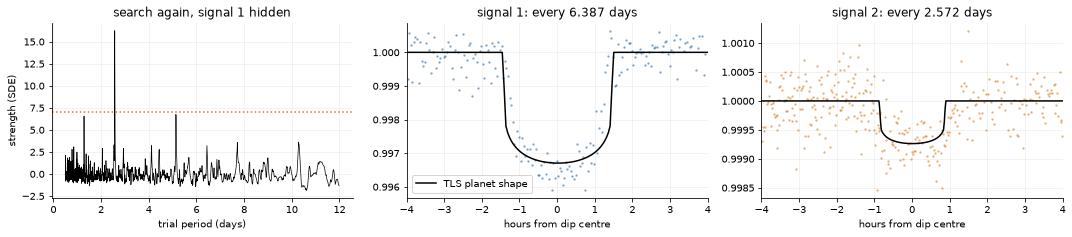

In [8]:
remaining = common.hide_transits(lc, wide1)
wide2, fine2 = common.two_pass(remaining, star, CONFIG)
final2 = fine2 if fine2 is not None else wide2
print(f'removed {len(lc) - len(remaining):,} of {len(lc):,} points; second signal: {final2.period:.4f} days, SDE {wide2.SDE:.1f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
axes[0].plot(wide2.periods, wide2.power, color='k', lw=.7)
axes[0].axhline(common.MIN_SDE, color=PAL[1], ls=':')
axes[0].set(xlabel='trial period (days)', ylabel='strength (SDE)', title='search again, signal 1 hidden')
t2, y2, _ = clean_and_stitch([remaining], CONFIG['bin_minutes'], ephemeris=(wide2.period, wide2.T0, wide2.duration))
for ax, tt, ff, r, n in [(axes[1], tm, ym, fine1, 1), (axes[2], t2, y2, final2, 2)]:
    h = phase_offset(tt, r.period, r.T0) * 24
    near = np.abs(h) < 4
    ax.plot(h[near], ff[near], '.', ms=3, alpha=.4, color=PAL[n - 1])
    ax.plot((r.model_folded_phase - .5) * r.period * 24, r.model_folded_model, color='k', lw=1.5, label='TLS planet shape')
    ax.set(xlim=(-4, 4), xlabel='hours from dip centre', title=f'signal {n}: every {r.period:.3f} days')
axes[1].legend(loc='lower left'); plt.tight_layout(); plt.show()

## Check each dip

A tall search peak is only a start. The measuring code (`vet_signal`) looks at every single dip: how many had data, how many are clear on their own, and whether odd and even dips match (two stars orbiting each other often give alternating depths). These measurements become the model's numbers in chapter 5.

,observed_transits,significant_events,depth_ppm,pink_snr,odd_even_sigma,secondary_snr,centroid_snr,flags
signal 1,4,4,2554.33,34.52,2.71,-1.5,6.19,centroid_shift_requires_pixel_review
signal 2,8,6,674.53,11.19,0.93,2.1,2.01,none


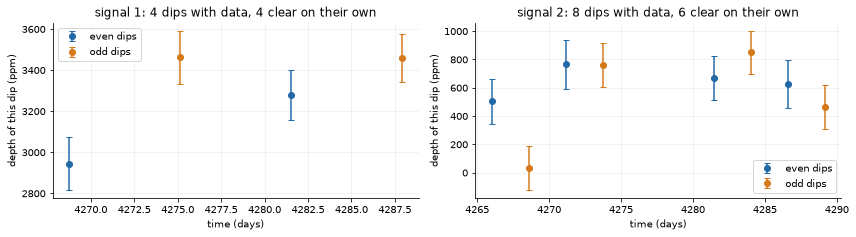

In [9]:
vet_data, _ = preprocess(path, CONFIG)
vets = [vet_signal(vet_data, r.period, r.T0, r.duration) for r in [fine1, final2]]
display(pd.DataFrame([{k: v[k] for k in ['observed_transits', 'significant_events', 'depth_ppm', 'pink_snr',
                                         'odd_even_sigma', 'secondary_snr', 'centroid_snr']} | {'flags': '; '.join(v['flags']) or 'none'}
                      for v in vets], index=['signal 1', 'signal 2']).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, v, n in zip(axes, vets, [1, 2]):
    ev = pd.DataFrame(v['events'])
    for parity, lab, c in [(0, 'even dips', PAL[0]), (1, 'odd dips', PAL[1])]:
        e = ev[ev.cycle % 2 == parity]
        ax.errorbar(e.epoch_btjd, e.depth * 1e6, e.depth_error * 1e6, fmt='o', capsize=3, color=c, label=lab)
    ax.set(xlabel='time (days)', ylabel='depth of this dip (ppm)',
           title=f"signal {n}: {v['observed_transits']} dips with data, {v['significant_events']} clear on their own")
    ax.legend()
plt.tight_layout(); plt.show()

## The bigger datasets are searched a little differently

For the training stars (`02_build_dataset.py`) we use up to 8 sectors (16 in dataset_v2), periods up to 30 days, and search each **block of up to 4 consecutive sectors** separately (TLS gets dip lengths wrong on years of gappy data). Signals found in several blocks are merged. Below: a made-up observing schedule, grouped by the pipeline's own functions.

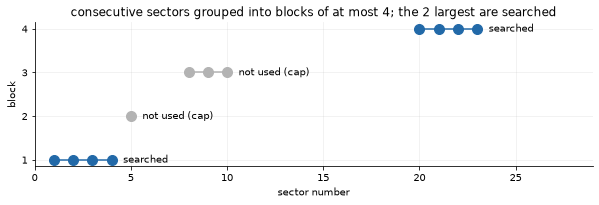

In [10]:
sectors = [1, 2, 3, 4, 5, 8, 9, 10, 20, 21, 22, 23]
fake_paths = [f'example-s{s:04d}-lc.fits' for s in sectors]       # file names only, no data
kept = set(m2.capped(fake_paths))
fig, ax = plt.subplots(figsize=(10, 2.6))
for i, block in enumerate(m2.chunks(fake_paths)):
    secs = [int(p.split('-s')[1][:4]) for p in block]
    used = all(p in kept for p in block)
    ax.plot(secs, [i + 1] * len(secs), 'o-', ms=10, color=PAL[0] if used else '0.7')
    ax.text(max(secs) + .6, i + 1, 'searched' if used else 'not used (cap)', va='center')
ax.set(xlabel='sector number', ylabel='block', yticks=range(1, i + 2), xlim=(0, 29),
       title=f'consecutive sectors grouped into blocks of at most {m2.CHUNK_SECTORS}; the {m2.MAX_CHUNKS} largest are searched')
plt.show()

<a id="ch3"></a>
# Chapter 3: Is it a known planet?

**What you'll learn:** how we check a found period against the planet catalogue, and how often the search finds the known planets of the 100 benchmark stars.

A found signal **matches** a catalogued planet if the periods agree within 1%. (Half or double the period is noted separately: that's the same dips, counted differently.) The catalogue is used only now, after the search.

In [11]:
known = pd.read_csv(ROOT / 'data/benchmark/known_planets.csv')
planets = known[known.tic.eq(TIC) & known.tran_flag.eq(1)
                & known.pl_orbper.between(CONFIG['period_min_days'], CONFIG['period_max_days'])]
match = pd.DataFrame([{'our signal': n, 'our period (days)': r.period, 'catalogue planet': p.pl_name,
                       'catalogue period (days)': p.pl_orbper, 'match': common.relation(r.period, p.pl_orbper) or '-'}
                      for n, r in [(1, fine1), (2, final2)] for p in planets.itertuples()])
display(match.round(4))
saved = bench.set_index('tic').loc[TIC]
print(f"stored benchmark run: {saved.period:.4f} and {saved.s2_period:.4f} days; this run: {fine1.period:.4f} and {final2.period:.4f}")
assert (match['match'] == 'exact').sum() == 2      # both signals are known planets

,our signal,our period (days),catalogue planet,catalogue period (days),match
0,1,6.3872,TOI-880 c,6.3873,exact
1,1,6.3872,TOI-880.02,2.5757,-
2,2,2.5716,TOI-880 c,6.3873,-
3,2,2.5716,TOI-880.02,2.5757,exact


stored benchmark run: 6.3872 and 2.5716 days; this run: 6.3872 and 2.5716


## All 100 benchmark stars

A known planet counts as **found** if one of our two signals has SDE ≥ 7 and its period matches. On the 40 stars without known planets, any SDE ≥ 7 signal is a **flag** (worth a look, not proven fake).

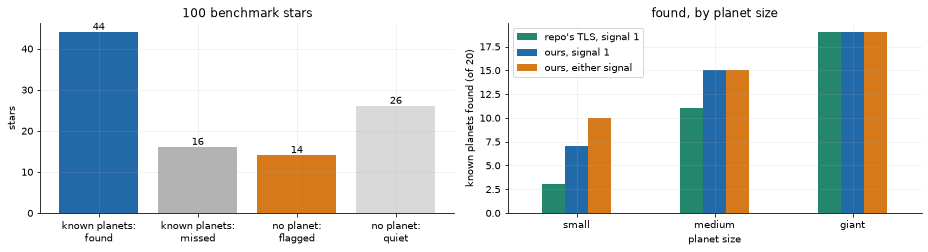

In [12]:
b = bench.copy()
b['first'] = b.sde.ge(common.MIN_SDE) & b.match.eq('exact')
b['either'] = b['first'] | (b.s2_sde.ge(common.MIN_SDE) & b.s2_match.eq('exact'))
hosts = b[b.catalog_group.eq('known_transiting_host')].merge(bench_hosts[['tic', 'repo_tls_exact']], on='tic')
others = b[b.catalog_group.eq('no_cataloged_transiting_planet')]
found, flagged = int(hosts.either.sum()), int(others.detected.sum())
assert (len(hosts), len(others)) == (60, 40) and (found, flagged) == (44, 14)   # the README's benchmark numbers
recovery = hosts.groupby('radius_bin')[['repo_tls_exact', 'first', 'either']].sum().reindex(['small', 'medium', 'giant'])
recovery.columns = ["repo's TLS, signal 1", 'ours, signal 1', 'ours, either signal']

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
bars = axes[0].bar(['known planets:\nfound', 'known planets:\nmissed', 'no planet:\nflagged', 'no planet:\nquiet'],
                   [found, 60 - found, flagged, 40 - flagged], color=[PAL[0], '0.7', PAL[1], '0.85'])
axes[0].bar_label(bars); axes[0].set(ylabel='stars', title='100 benchmark stars')
recovery.plot.bar(ax=axes[1], color=[PAL[2], PAL[0], PAL[1]], rot=0)
axes[1].set(ylabel='known planets found (of 20)', xlabel='planet size', title='found, by planet size')
plt.tight_layout(); plt.show()
assert hosts.either.sum() > hosts['first'].sum() and recovery.idxmin().iloc[2] == 'small'

The second search finds extra planets the first misses, and small planets are the hardest. Of the misses, about 9 are too faint or show too few dips in one month **(from the README)**.

<a id="ch4"></a>
# Chapter 4: Labels: NASA's verdicts become training answers

**What you'll learn:** which found dips become "planet" or "fake" training examples, and which are left out on purpose.

NASA's experts have checked many TOIs and given each a verdict. A found dip gets that verdict only if its period matches the TOI's period on the same star.

| NASA verdict / situation | what we do |
|---|---|
| CP / KP (confirmed / known planet) | **planet** |
| FP / FA (false positive / false alarm) | **fake** |
| PC / APC (still undecided) | never trained on; ranked at the end |
| dip matches no TOI | **left out**: it could be an unlisted planet, or noise; we don't know |
| NT: a dip on a random star with no TOI | "nothing here": used as fake only when asked (`--nt`, chapter 9) |

,dataset,dataset_v2
label,,
planet,1112,1123
fake,631,641
undecided,23,23
matches no TOI,3788,3948
random star (NT),0,2464


load: dropped 18 rows ({'FP': 13, 'FA': 4, 'KP': 1}) of 18 stars with no light curve of their own


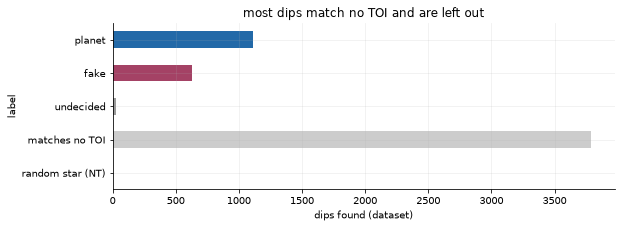

In [13]:
group = {'CP': 'planet', 'KP': 'planet', 'FP': 'fake', 'FA': 'fake', 'PC': 'undecided', 'APC': 'undecided',
         'NT': 'random star (NT)', 'none': 'matches no TOI'}
counts = pd.DataFrame({n: signals[n].label.map(group).value_counts() for n in ['dataset', 'dataset_v2']}).fillna(0).astype(int)
counts = counts.loc[['planet', 'fake', 'undecided', 'matches no TOI', 'random star (NT)']]
display(counts)
used = m3.load()   # what training actually uses (prints the 18 dropped wrong-star rows: chapter 11)
assert set(used.label) == {'CP', 'KP', 'FP', 'FA'} and len(used) == len(df)

fig, ax = plt.subplots(figsize=(9, 3))
counts['dataset'].plot.barh(ax=ax, color=[PAL[0], PAL[3], '0.6', '0.8', PAL[2]])
ax.set(xlabel='dips found (dataset)', title='most dips match no TOI and are left out')
ax.invert_yaxis(); plt.show()

Matching is by period, so a few matches can still be wrong. Leaving the unmatched dips out keeps the training answers trustworthy; earlier versions counted them as fakes, which made the task look easier than it is.

<a id="ch5"></a>
# Chapter 5: The 12 measurements

**What you'll learn:** the 12 numbers the models get about each dip, in four groups, each shown on a real star next to how often it occurs for NASA planets vs fakes.

The models get three kinds of input about each dip. This chapter covers the **numbers**; chapter 6 the **pictures** (snapshots); chapter 8 the **pixel images**.

- **Snapshots = pictures.** Each is a curve: the dip's brightness drawn as 61 (or 201) points. There are 6 per dip.
- **Measurements = single numbers**, like "dip depth = 1.9%". There are 12 per dip.

From here on we use four example dips from the training set (their raw files are kept locally):

- **A**: a known planet with a big, clear dip.
- **B**: a fake: two stars orbiting each other, which also dim each other halfway round the orbit.
- **C**: a fake: the star's measured position moves during every dip, so the dip really comes from a neighbouring star.
- **D**: a fake where every other dip is deeper (two stars of different sizes).

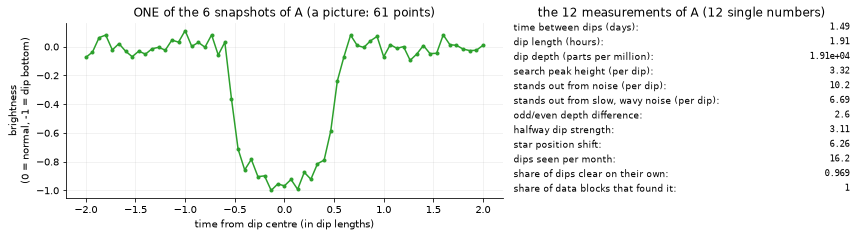

,star (TIC),period (days),dip depth (%),dip length (hours),NASA verdict,tree score (numbers only),shape-model score
A,273874849,1.49,1.91,1.9,known planet,0.1079,0.7007
B,96291218,13.71,0.15,5.8,fake,0.0135,0.0094
C,279999655,1.54,0.41,1.9,fake,0.6184,0.0016
D,349790953,1.55,0.26,4.1,fake,0.0065,0.0312


In [14]:
A = ex['A']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1.3, 1]})
a1.plot(np.linspace(-2, 2, m4.LOCAL_BINS), npz['local'][A.view_row], 'o-', ms=3, color=COLORS['A'])
a1.set(title='ONE of the 6 snapshots of A (a picture: 61 points)', xlabel='time from dip centre (in dip lengths)',
       ylabel='brightness\n(0 = normal, -1 = dip bottom)')
a2.axis('off')
a2.set_title('the 12 measurements of A (12 single numbers)')
for i, (col, name) in enumerate(PLAIN.items()):
    a2.text(0, 1 - i / 12, f'{name}:', fontsize=9, va='top')
    a2.text(1, 1 - i / 12, f'{A[col]:.3g}', fontsize=9, va='top', ha='right', family='monospace')
plt.tight_layout(); plt.show()

table = pd.DataFrame.from_dict(orient='index', data={k: {
    'star (TIC)': r.tic, 'period (days)': round(r.period, 2), 'dip depth (%)': round(r.depth_ppm / 1e4, 2),
    'dip length (hours)': round(r.duration_h, 1), 'NASA verdict': VERDICT[r.label],
    'tree score (numbers only)': round(r.gbt, 4), 'shape-model score': round(r.views_features, 4)} for k, r in ex.items()})
display(table)
assert [r.y for r in ex.values()] == [1, 0, 0, 0]
assert ex['A'].gbt < 0.5 < ex['A'].views_features
assert ex['C'].views_features < 0.5 < ex['C'].gbt
assert all(ex[k].gbt < 0.5 and ex[k].views_features < 0.5 for k in 'BD')

The two scores come from the stored results of the two models in chapter 7, each from a model that never saw that star. The simpler **tree model** (numbers only) calls planet A a fake and fake C a planet; the **shape model** gets all four right (the `assert` lines check this).

## Why "per dip"?

The measuring code (`vet_signal`, chapter 2) runs on 10-minute data. Below we rerun it on the examples and check it gives exactly the stored numbers.

Some numbers are given **per dip**: divided by the square root of the number of dips. Combining more dips makes any signal look stronger (noise shrinks like 1/√dips), and NASA watches planet stars longer. Without this, the model could learn "more data means planet", which is useless.

re-measured values match the stored ones for A, B, C and D


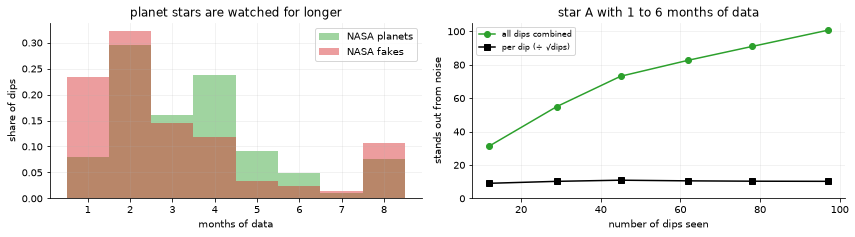

In [15]:
def measure_data(path_list):
    # The 10-minute data the measurements are made on (as in 02_build_dataset.search_star), per sector
    parts = []
    for p in path_list:
        try:
            parts.append(m2.preprocess(p, m2.CONFIG)[0])
        except ValueError:          # sector rejected by the quality checks
            pass
    return {k: np.concatenate([d[k] for d in parts]) for k in ['time', 'flux', 'error', 'centroid1', 'centroid2']}, parts

mdata, mparts, vet = {}, {}, {}
for k, r in ex.items():
    mdata[k], mparts[k] = measure_data(paths[k])
    vet[k] = vet_signal(mdata[k], r.period, r.t0, r.duration_h / 24)
    for col in ['depth_ppm', 'depth_snr', 'pink_snr', 'odd_even_sigma', 'secondary_snr', 'centroid_snr',
                'observed_transits', 'significant_events']:
        assert np.isclose(vet[k][col], r[col]), (k, col)
print('re-measured values match the stored ones for A, B, C and D')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
    g = df[df.y == yy]
    axes[0].hist(g.sectors, np.arange(0.5, 9.5), weights=np.full(len(g), 1 / len(g)), alpha=.45, color=c, label=lab)
grow = []   # star A measured on its first 1, 2, ... months of data
for n in range(1, len(mparts['A']) + 1):
    part = {k: np.concatenate([d[k] for d in mparts['A'][:n]]) for k in mdata['A']}
    v = vet_signal(part, A.period, A.t0, A.duration_h / 24)
    grow.append((v['observed_transits'], v['depth_snr']))
grow = np.array(grow)
axes[1].plot(grow[:, 0], grow[:, 1], 'o-', color=COLORS['A'], label='all dips combined')
axes[1].plot(grow[:, 0], grow[:, 1] / np.sqrt(grow[:, 0]), 's-', color='k', label='per dip (÷ √dips)')
axes[1].legend(fontsize=8)
axes[0].set(title='planet stars are watched for longer', xlabel='months of data', ylabel='share of dips')
axes[1].set(title=f'star A with 1 to {len(grow)} months of data', xlabel='number of dips seen', ylabel='stands out from noise', ylim=(0, None))
axes[0].legend(); plt.tight_layout(); plt.show()

### Group 1: the dip itself

- **Period** (days): how long one orbit takes. Very short periods are common for two-star pairs.
- **Dip length** (hours): for a planet it follows from the star's size and the orbit; too long or too short is suspicious.
- **Dip depth** (ppm): a planet can only block so much light; very deep dips (several %) are usually two stars.

Top: what they mean on star A. Bottom: how often each value occurs for NASA planets vs fakes (dashed lines: our examples).

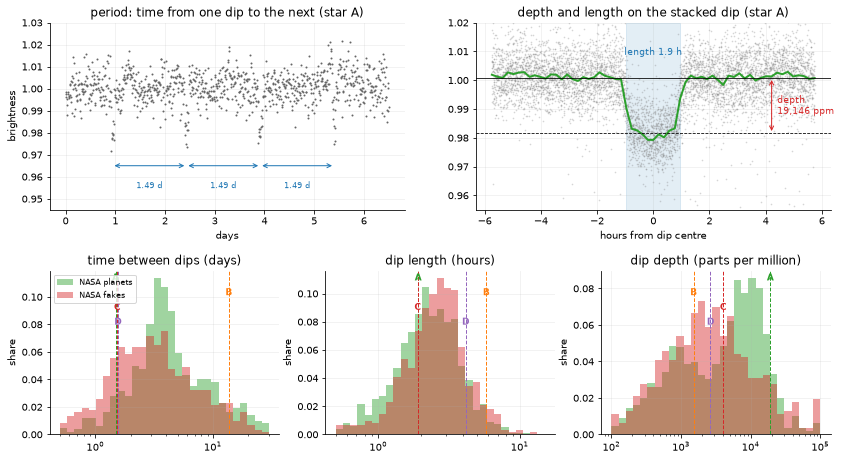

In [16]:
def class_hist(ax, col, lo, hi, log=False):
    # Share of NASA planets / fakes at each value of one measurement; examples marked
    v = df[col].replace([np.inf, -np.inf], np.nan)
    bins = np.geomspace(lo, hi, 30) if log else np.linspace(lo, hi, 30)
    for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        x = v[df.y == yy].dropna().clip(lo, hi)
        ax.hist(x, bins, weights=np.full(len(x), 1 / len(x)), alpha=.45, color=c, label=lab)
    for n, (k, r) in enumerate(ex.items()):
        if np.isfinite(r[col]):
            ax.axvline(np.clip(r[col], lo, hi), color=COLORS[k], ls='--', lw=1)
            ax.text(np.clip(r[col], lo, hi), ax.get_ylim()[1] * (.94 - .09 * n), k, color=COLORS[k], fontsize=9,
                    ha='center', fontweight='bold')
    ax.set(xscale='log' if log else 'linear', title=PLAIN[col], ylabel='share')

P, T0, DUR = A.period, A.t0, A.duration_h / 24          # days
lcs = {k: [lk.read(p, flux_column='pdcsap_flux') for p in paths[k]] for k in 'ABC'}
month = lcs['A'][0].remove_nans().normalize()
t_raw = month.time.value
t_cl, f_cl, _ = clean_and_stitch([lcs['A'][0]], bin_minutes=10, ephemeris=(P, T0, DUR))

fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['period', 'shape']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['period', 'duration_h', 'depth_ppm']], gridspec_kw={'top': .42, 'bottom': .07})

ax = top['period']
d = np.flatnonzero(t_cl < t_cl[0] + 6.5)
ax.plot(t_cl[d] - t_raw[0], f_cl[d], '.', ms=2, color='0.4')
centres = T0 + P * np.arange(np.ceil((t_cl[0] - T0) / P), np.floor((t_cl[d[-1]] - T0) / P) + 1)
for c0, c1 in zip(centres[:-1], centres[1:]):
    ax.annotate('', xy=(c1 - t_raw[0], 0.965), xytext=(c0 - t_raw[0], 0.965), arrowprops=dict(arrowstyle='<->', color='tab:blue'))
    ax.text((c0 + c1) / 2 - t_raw[0], 0.958, f'{P:.2f} d', ha='center', va='top', fontsize=8, color='tab:blue')
ax.set(title='period: time from one dip to the next (star A)', xlabel='days', ylabel='brightness', ylim=(0.945, 1.03))

ax = top['shape']
dm = mdata['A']
x = phase_offset(dm['time'], P, T0) * 24
w = np.abs(x) < 3 * A.duration_h
ax.plot(x[w], dm['flux'][w], '.', ms=1.5, alpha=.25, color='0.5')
b, _ = m4.binned(x[w], dm['flux'][w], -3 * A.duration_h, 3 * A.duration_h, 61)
ax.plot(np.linspace(-3, 3, 61) * A.duration_h, b, color=COLORS['A'], lw=2)
base_A = np.median(dm['flux'][np.abs(x) > A.duration_h])
ax.axhline(base_A, color='k', lw=.8); ax.axhline(base_A - A.depth_ppm / 1e6, color='k', lw=.8, ls='--')
ax.annotate('', xy=(2.2 * A.duration_h, base_A - A.depth_ppm / 1e6), xytext=(2.2 * A.duration_h, base_A),
            arrowprops=dict(arrowstyle='<->', color='tab:red'))
ax.text(2.25 * A.duration_h, base_A - A.depth_ppm / 2e6, f' depth\n {A.depth_ppm:,.0f} ppm', color='tab:red', va='center', fontsize=9)
ax.axvspan(-A.duration_h / 2, A.duration_h / 2, color='tab:blue', alpha=.12)
ax.text(0, base_A + 0.008, f'length {A.duration_h:.1f} h', color='tab:blue', ha='center', fontsize=9)
ax.set(title='depth and length on the stacked dip (star A)', xlabel='hours from dip centre', ylim=(0.955, 1.02))

class_hist(bottom['period'], 'period', 0.5, 30, log=True)
class_hist(bottom['duration_h'], 'duration_h', 0.5, 15, log=True)
class_hist(bottom['depth_ppm'], 'depth_ppm', 100, 1e5, log=True)
bottom['period'].legend(fontsize=8, loc='upper left')
plt.show()

NASA's planets here are often *deeper* than the fakes (many are big, well-known planets). Each of these three numbers alone separates planets and fakes only a little.

### Group 2: how clearly the dip stands out

- **Search peak height (SDE), per dip**: the height of the search peak (chapter 2).
- **Stands out from noise (depth SNR), per dip**: depth divided by its uncertainty (SNR = signal-to-noise ratio), assuming the noise is random from point to point.
- **Stands out from slow, wavy noise (pink SNR), per dip**: the same, but the noise is measured on dip-length averages. If the brightness wobbles slowly, those averages scatter more than random noise predicts, and the dip counts as less certain.

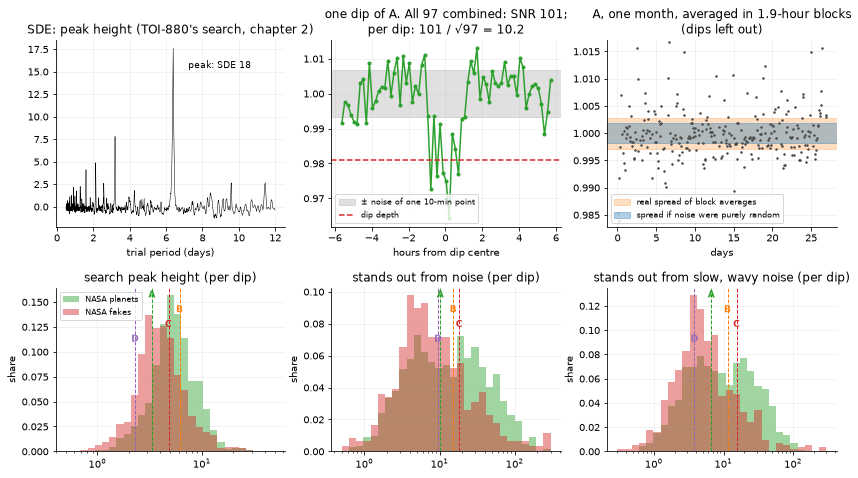

A: wavy-noise spread is 1.6x the purely random spread, so its pink SNR (66) is lower than its plain SNR (101)


In [17]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['sde', 'snr', 'pink']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['sde_per_transit', 'depth_snr_per_transit', 'pink_snr_per_transit']],
                            gridspec_kw={'top': .42, 'bottom': .07})

ax = top['sde']
ax.plot(wide1.periods, wide1.power, lw=.5, color='k')
ax.annotate(f'peak: SDE {wide1.SDE:.0f}', (wide1.period, wide1.SDE), xytext=(15, -20), textcoords='offset points', fontsize=9)
ax.set(title="SDE: peak height (TOI-880's search, chapter 2)", xlabel='trial period (days)')

ax = top['snr']
dm = mdata['A']; ph = phase_offset(dm['time'], P, T0); cyc = np.rint((dm['time'] - T0) / P).astype(int)
ev = vet['A']['events'][len(vet['A']['events']) // 2]          # one typical dip
one = (cyc == ev['cycle']) & (np.abs(ph) < 3 * DUR)
noise = robust_sigma(dm['flux'][np.abs(ph) > DUR])
ax.plot(ph[one] * 24, dm['flux'][one], 'o-', ms=3, color=COLORS['A'])
ax.axhspan(1 - noise, 1 + noise, color='0.6', alpha=.3, label='± noise of one 10-min point')
ax.axhline(1 - A.depth_ppm / 1e6, color='tab:red', ls='--', label='dip depth')
ax.legend(fontsize=8, loc='lower left')
n_dips = vet['A']['observed_transits']
ax.set(title=f'one dip of A. All {n_dips} combined: SNR {A.depth_snr:.0f};\nper dip: {A.depth_snr:.0f} / √{n_dips} = {A.depth_snr_per_transit:.1f}',
       xlabel='hours from dip centre')

ax = top['pink']
out = np.abs(ph) > DUR
labels = np.floor((dm['time'] - dm['time'].min()) / max(DUR, .025)).astype(int)   # dip-length blocks, as vet_signal
blk = []   # (time, average brightness, its uncertainty if the noise were purely random) per block
for lab in np.unique(labels):
    bb = (labels == lab) & out
    if bb.sum() >= 3:
        blk.append((dm['time'][bb].mean(), *weighted_mean(dm['flux'][bb], dm['error'][bb])))
blk = np.array(blk)
block_noise = robust_sigma(blk[:, 1])
white = np.median(blk[:, 2])
depth_err = (A.depth_ppm / 1e6) / A.depth_snr
assert np.isclose(A.depth_ppm / 1e6 / max(depth_err, block_noise / np.sqrt(n_dips)), A.pink_snr)
first = blk[:, 0] < blk[0, 0] + 27
ax.plot(blk[first, 0] - blk[0, 0], blk[first, 1], '.', ms=3, color='0.3')
ax.axhspan(1 - block_noise, 1 + block_noise, color='tab:orange', alpha=.25, label='real spread of block averages')
ax.axhspan(1 - white, 1 + white, color='tab:blue', alpha=.35, label='spread if noise were purely random')
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'A, one month, averaged in {A.duration_h:.1f}-hour blocks\n(dips left out)', xlabel='days',
       ylim=(1 - 6 * block_noise, 1 + 6 * block_noise))

class_hist(bottom['sde_per_transit'], 'sde_per_transit', 0.5, 50, log=True)
class_hist(bottom['depth_snr_per_transit'], 'depth_snr_per_transit', 0.5, 300, log=True)
class_hist(bottom['pink_snr_per_transit'], 'pink_snr_per_transit', 0.3, 300, log=True)
bottom['sde_per_transit'].legend(fontsize=8, loc='upper left')
plt.show()
print(f'A: wavy-noise spread is {block_noise / white:.1f}x the purely random spread, '
      f'so its pink SNR ({A.pink_snr:.0f}) is lower than its plain SNR ({A.depth_snr:.0f})')

The middle and right pictures use the exact data and noise rules of the stored measurements (the `assert` recomputes A's pink SNR). Planets tend to stand out more clearly than fakes on all three.

### Group 3: warning signs of a fake

- **Odd/even depth difference**: odd dips (1, 3, 5...) vs even dips, in "sigmas" (difference ÷ its uncertainty; 3 or more = a real difference). Two stars of different sizes give alternating depths.
- **Halfway dip strength**: how much dimmer the star is exactly half an orbit after the dip. A two-star pair often dims there too.
- **Star position shift**: TESS records where the light is centred on the camera. If that centre moves during every dip, the dimming is really on a nearby star.

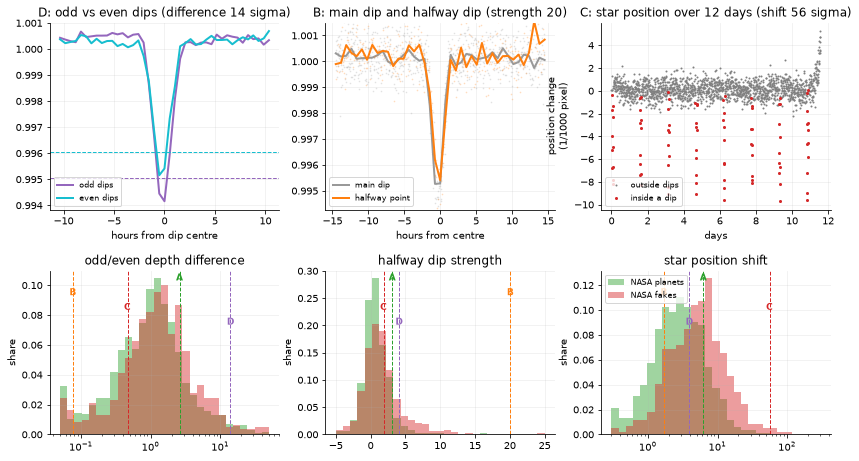

In [18]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['oe', 'half', 'pos']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['odd_even_sigma', 'secondary_snr', 'centroid_snr']], gridspec_kw={'top': .42, 'bottom': .07})

def folded_hours(k, shift=0.0):
    # 10-minute measurement data of example k, as hours from the dip (or from `shift` orbits after it)
    r, dm = ex[k], mdata[k]
    x = phase_offset(dm['time'], r.period, r.t0 + shift * r.period) * 24
    return x, dm['flux'], np.rint((dm['time'] - r.t0) / r.period).astype(int)

ax = top['oe']
r = ex['D']; x, fl, cyc = folded_hours('D'); win3 = np.abs(x) < 2.5 * r.duration_h
events = pd.DataFrame(vet['D']['events'])
for parity, lab, c in [(1, 'odd dips', 'tab:purple'), (0, 'even dips', 'tab:cyan')]:
    s = win3 & (cyc % 2 == parity)
    bb, _ = m4.binned(x[s], fl[s], -2.5 * r.duration_h, 2.5 * r.duration_h, 41)
    ax.plot(np.linspace(-2.5, 2.5, 41) * r.duration_h, bb, color=c, lw=2, label=lab)
    e = events[events.cycle % 2 == parity]
    depth, _ = weighted_mean(e.depth.values, e.depth_error.values)
    ax.axhline(1 - depth, color=c, ls='--', lw=1)
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'D: odd vs even dips (difference {r.odd_even_sigma:.0f} sigma)', xlabel='hours from dip centre')

ax = top['half']
r = ex['B']
lowest = []
for shift, lab, c in [(0, 'main dip', '0.6'), (0.5, 'halfway point', COLORS['B'])]:
    x, fl, _ = folded_hours('B', shift); s = np.abs(x) < 2.5 * r.duration_h
    ax.plot(x[s], fl[s], '.', ms=1.5, alpha=.2, color=c)
    bb, _ = m4.binned(x[s], fl[s], -2.5 * r.duration_h, 2.5 * r.duration_h, 41)
    ax.plot(np.linspace(-2.5, 2.5, 41) * r.duration_h, bb, color=c, lw=2, label=lab)
    lowest.append(bb.min())
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'B: main dip and halfway dip (strength {r.secondary_snr:.0f})', xlabel='hours from centre',
       ylim=(min(lowest) - 0.001, 1.0015))

ax = top['pos']
r, dm = ex['C'], mdata['C']
inside = np.abs(phase_offset(dm['time'], r.period, r.t0)) < r.duration_h / 48
outside = np.abs(phase_offset(dm['time'], r.period, r.t0)) > r.duration_h / 24
col = max(['centroid1', 'centroid2'], key=lambda c: abs(np.nanmean(dm[c][inside]) - np.nanmean(dm[c][outside])))
s = dm['time'] < dm['time'].min() + 12
ax.plot(dm['time'][s] - dm['time'][0], dm[col][s] * 1000, '.', ms=2, color='0.5', label='outside dips')
ax.plot(dm['time'][s & inside] - dm['time'][0], dm[col][s & inside] * 1000, '.', ms=4, color=COLORS['C'], label='inside a dip')
ax.legend(fontsize=8, loc='lower left')
ax.set(title=f'C: star position over 12 days (shift {r.centroid_snr:.0f} sigma)', xlabel='days',
       ylabel='position change\n(1/1000 pixel)')

class_hist(bottom['odd_even_sigma'], 'odd_even_sigma', 0.05, 50, log=True)
class_hist(bottom['secondary_snr'], 'secondary_snr', -5, 25)
class_hist(bottom['centroid_snr'], 'centroid_snr', 0.3, 300, log=True)
bottom['centroid_snr'].legend(fontsize=8, loc='upper left')
plt.show()

D's odd dips are deeper than its even ones; B dims again halfway round its orbit; C's position jumps at every dip. Fakes have a long tail of large values on all three, but many fakes look clean here, so none is a perfect test alone.

### Group 4: how consistently the dip shows up

- **Dips seen per month**: dips with data ÷ months of data.
- **Share of dips clear on their own**: a dip whose depth is 3+ times its own uncertainty counts as "clear".
- **Share of data blocks that found it**: a real signal should be found in every block of consecutive months (chapter 2); a one-off glitch only in one.

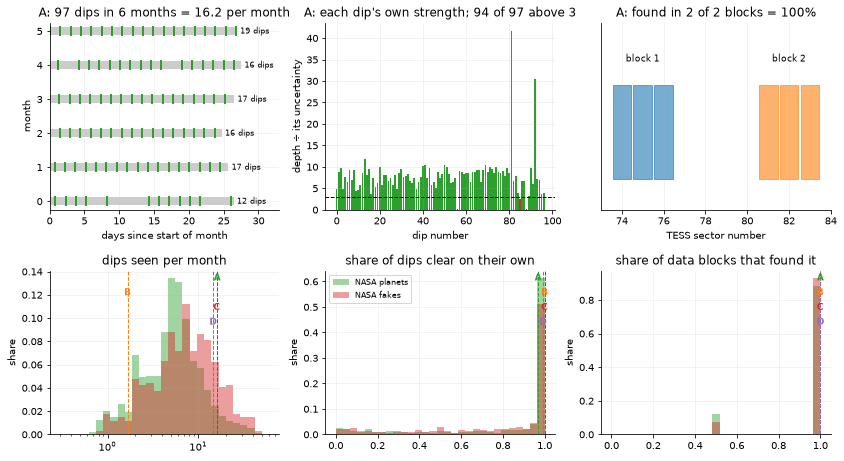

,A (known planet),B (fake),C (fake),D (fake)
time between dips (days),1.49,13.71,1.54,1.55
dip length (hours),1.91,5.81,1.90,4.14
dip depth (parts per million),19146.50,1518.39,4050.75,2634.57
search peak height (per dip),3.32,6.11,4.79,2.27
stands out from noise (per dip),10.22,15.21,18.27,9.45
"stands out from slow, wavy noise (per dip)",6.69,11.45,15.43,3.79
odd/even depth difference,2.60,0.08,0.47,14.01
halfway dip strength,3.11,20.09,1.87,4.08
star position shift,6.26,1.70,55.98,3.92
dips seen per month,16.17,1.67,16.00,14.50


In [19]:
fig = plt.figure(figsize=(14, 6.5))
top = fig.subplot_mosaic([['months', 'events', 'blocks']], gridspec_kw={'bottom': .55, 'top': .95})
bottom = fig.subplot_mosaic([['transits_per_sector', 'significant_event_fraction', 'chunk_fraction']],
                            gridspec_kw={'top': .42, 'bottom': .07})

ax = top['months']
dip_times = np.array([e['epoch_btjd'] for e in vet['A']['events']])
for i, ts in enumerate(d['time'] for d in mparts['A']):
    ax.plot([0, ts.max() - ts.min()], [i, i], color='0.8', lw=8, solid_capstyle='butt')
    mine = dip_times[(dip_times >= ts.min()) & (dip_times <= ts.max())]
    ax.plot(mine - ts.min(), np.full(len(mine), i), '|', color=COLORS['A'], ms=10, mew=2)
    ax.text(ts.max() - ts.min() + 0.5, i, f'{len(mine)} dips', va='center', fontsize=8)
ax.set(title=f'A: {len(dip_times)} dips in {len(mparts["A"])} months = {A.transits_per_sector:.1f} per month',
       xlabel='days since start of month', ylabel='month', xlim=(0, 33), yticks=range(len(mparts['A'])))

ax = top['events']
snr = np.array([e['snr'] for e in vet['A']['events']])
ax.bar(range(len(snr)), snr, color=np.where(snr >= 3, COLORS['A'], 'tab:red'))
ax.axhline(3, color='k', ls='--', lw=1)
ax.set(title=f"A: each dip's own strength; {(snr >= 3).sum()} of {len(snr)} above 3",
       xlabel='dip number', ylabel='depth ÷ its uncertainty')

ax = top['blocks']
sector_no = lambda p: int(p.split('-s')[1][:4])
for bi, grp in enumerate(m2.chunks(paths['A'])):
    for p in grp:
        ax.add_patch(plt.Rectangle((sector_no(p) - 0.45, 0.2), 0.9, 0.6, color=f'C{bi}', alpha=.6))
    ax.text(np.mean([sector_no(p) for p in grp]), 0.95, f'block {bi + 1}', ha='center', fontsize=9)
secs = [sector_no(p) for p in paths['A']]
ax.set(xlim=(min(secs) - 1, max(secs) + 1), ylim=(0, 1.2), yticks=[], xlabel='TESS sector number',
       title=f'A: found in {A.n_chunks_found} of {A.chunks:.0f} blocks = {A.chunk_fraction:.0%}')

class_hist(bottom['transits_per_sector'], 'transits_per_sector', 0.3, 60, log=True)
class_hist(bottom['significant_event_fraction'], 'significant_event_fraction', 0, 1)
class_hist(bottom['chunk_fraction'], 'chunk_fraction', 0, 1)
bottom['significant_event_fraction'].legend(fontsize=8, loc='upper left')
plt.show()

meas = pd.DataFrame({f'{k} ({VERDICT[r.label]})': [r[c] for c in PLAIN] for k, r in ex.items()}, index=list(PLAIN.values()))
display(meas.round(2))

The table matches the pictures: B has a strong halfway dip, C a large position shift, D a large odd/even difference. A's warning signs are small; its *size* numbers are what pictures alone can't show.

<a id="ch6"></a>
# Chapter 6: The snapshots: six pictures of the dip

**What you'll learn:** how stacking every dip turns noise into a clean picture, the six pictures the model sees, and what the average planet and the average fake look like.

One dip alone is noisy. But we know the period, so we can cut the data every orbit and lay all the dips on top of each other, lined up on the dip centre. This is **folding**.

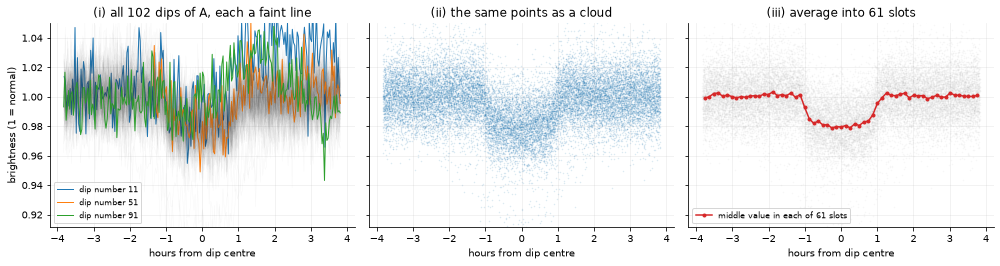

In [20]:
def cleaned_all(lc_list, period, t0, dur):
    # Same cleaning as the snapshot builder: each sector cleaned on its own, 2-minute points
    parts = [clean_and_stitch([lc], bin_minutes=2, ephemeris=(period, t0, dur)) for lc in lc_list]
    t = np.concatenate([np.asarray(p[0]) for p in parts])
    f = np.concatenate([np.ma.filled(p[1], np.nan) for p in parts])
    ok = np.isfinite(t) & np.isfinite(f)
    return t[ok], f[ok]

t, f = cleaned_all(lcs['A'], P, T0, DUR)
dt = phase_offset(t, P, T0)                  # days from the nearest dip centre
cycle = np.round((t - T0) / P).astype(int)   # which dip each point belongs to
W = m4.HALF_WINDOW * DUR                     # close-up window: +/- 2 dip lengths
win = np.abs(dt) < W
base = np.median(f[np.abs(dt) > DUR])        # normal brightness, measured away from the dips
local_raw, _ = m4.binned(dt, f, -W, W, m4.LOCAL_BINS)       # middle value in each of 61 time slots
edges = np.linspace(-W, W, m4.LOCAL_BINS + 1)
centres_h = (edges[:-1] + edges[1:]) / 2 * 24

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for n, k in enumerate(np.unique(cycle[win])):
    s = win & (cycle == k)
    axes[0].plot(dt[s] * 24, f[s], lw=.5, alpha=.04, color='0.3')
    if n in (10, 50, 90):   # three single dips, drawn strongly: each alone is mostly noise
        axes[0].plot(dt[s] * 24, f[s], lw=1, color=f'C{n // 40}', label=f'dip number {n + 1}')
axes[0].set_title(f'(i) all {len(np.unique(cycle[win]))} dips of A, each a faint line')
axes[0].legend(loc='lower left', fontsize=8)
axes[1].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.15, color='tab:blue')
axes[1].set_title('(ii) the same points as a cloud')
axes[2].plot(dt[win] * 24, f[win], '.', ms=1, alpha=.06, color='0.6')
axes[2].plot(centres_h, local_raw, 'o-', ms=3, color='tab:red', label='middle value in each of 61 slots')
axes[2].set_title('(iii) average into 61 slots')
axes[2].legend(loc='lower left', fontsize=8)
axes[0].set_ylabel('brightness (1 = normal)')
for ax in axes:
    ax.set_xlabel('hours from dip centre')
axes[0].set_ylim(np.percentile(f[win], [0.2, 99.9]))
plt.tight_layout(); plt.show()

Noise is random, so stacking ~100 dips and taking the middle value per time slot cancels it while the real shape stays. The result is the **close-up snapshot**. The model gets it **rescaled** (normal = 0, dip bottom = -1), so it shows *shape only, not size*; size comes from the numbers. The **whole-orbit snapshot** is the same over one full orbit (201 slots).

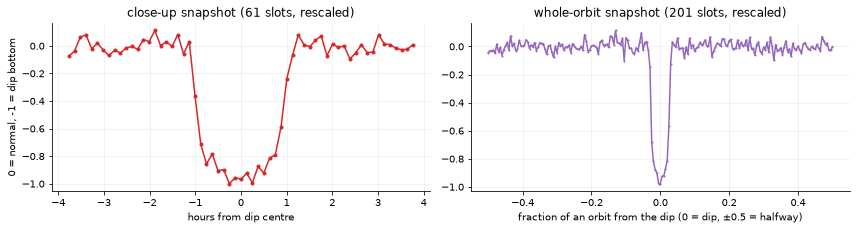

In [21]:
close_up = (local_raw - base) / (base - local_raw.min())
glob_raw, _ = m4.binned(dt / P, f, -0.5, 0.5, m4.GLOBAL_BINS)    # the whole orbit in 201 slots
whole = (glob_raw - base) / (base - local_raw.min())
assert np.allclose(close_up, npz['local'][A.view_row], atol=1e-5)  # identical to the model's input
assert np.allclose(whole, npz['global'][A.view_row], atol=1e-5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].plot(centres_h, close_up, 'o-', ms=3, color='tab:red')
axes[0].set(title='close-up snapshot (61 slots, rescaled)', xlabel='hours from dip centre', ylabel='0 = normal, -1 = dip bottom')
axes[1].plot(np.linspace(-0.5, 0.5, m4.GLOBAL_BINS), whole, '.-', ms=2, color='tab:purple')
axes[1].set(title='whole-orbit snapshot (201 slots, rescaled)', xlabel='fraction of an orbit from the dip (0 = dip, ±0.5 = halfway)')
plt.tight_layout(); plt.show()

## The six snapshots

Besides the whole orbit and the close-up: **odd** / **even** (only dips 1, 3, 5... / 2, 4, 6...), **halfway** (the same window half an orbit later) and **star position** (how much the light's centre moves; what matters is a rise during the dip). Below, all six for A, B and C, rebuilt from the raw files with the pipeline's code and checked against the stored ones.

| snapshot | the fake it helps catch |
|---|---|
| whole orbit | two stars: a second dip at the edges (halfway round) |
| close-up | two stars: a **V** shape. A planet gives a flat-bottomed **U** (it sits fully in front of the star for a while) |
| odd / even | two stars of different sizes: every other dip has a different depth |
| halfway | two stars: a small second dip when the dimmer star is hidden |
| star position | a neighbouring star: the light's centre shifts towards the star that is really dimming |

rebuilt snapshots match the stored ones for A, B and C


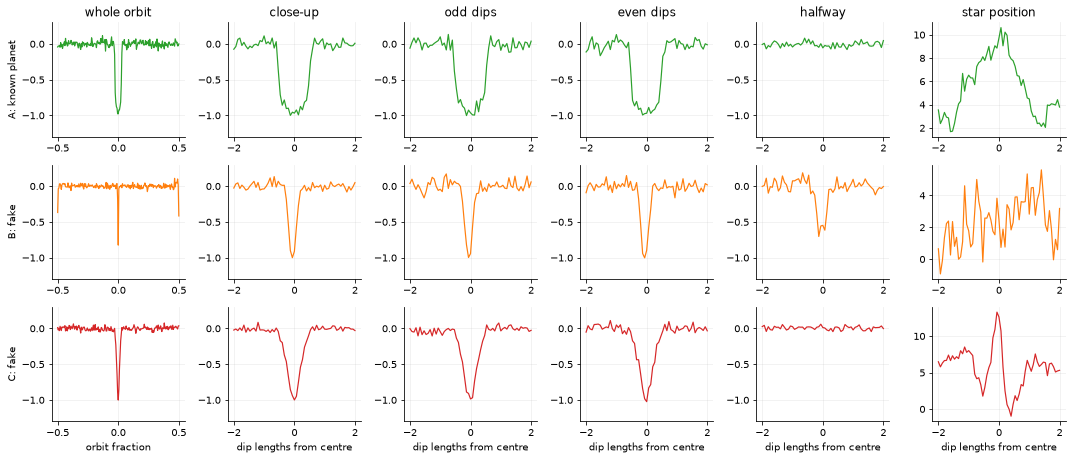

In [22]:
NAMES = {'global': 'whole orbit', 'local': 'close-up', 'odd': 'odd dips', 'even': 'even dips',
         'secondary': 'halfway', 'centroid': 'star position'}
snap = {}
for k in 'ABC':
    r = ex[k]
    snap[k], ok = m4.signal_views(lcs[k], r.period, r.t0, r.duration_h / 24)
    assert ok
    for name in NAMES:
        assert np.allclose(snap[k][name], npz[name][r.view_row], atol=1e-4), (k, name)
print('rebuilt snapshots match the stored ones for A, B and C')

x_local = np.linspace(-2, 2, m4.LOCAL_BINS)   # in dip lengths
fig, axes = plt.subplots(3, 6, figsize=(15, 6.5))
for i, k in enumerate('ABC'):
    for j, name in enumerate(NAMES):
        ax = axes[i, j]
        x = np.linspace(-0.5, 0.5, m4.GLOBAL_BINS) if name == 'global' else x_local
        ax.plot(x, snap[k][name], color=COLORS[k], lw=1.2)
        if name != 'centroid':
            ax.set_ylim(-1.3, 0.3)
        if i == 0:
            ax.set_title(NAMES[name])
        if i == 2:
            ax.set_xlabel('orbit fraction' if name == 'global' else 'dip lengths from centre')
    axes[i, 0].set_ylabel(f'{k}: {VERDICT[ex[k].label]}')
plt.tight_layout(); plt.show()

- **A** (planet): U-shaped dip with a flat floor; odd and even match; halfway is flat.
- **B** (two stars): a narrow dip, and a clear **halfway dip** (also at the edges of the whole-orbit picture).
- **C** (neighbour): a pointy dip, and the **position rises sharply** during the dip.

A's position picture also rises, almost as high as C's: a big dip on a star with neighbours nudges the measured centre a little. The matching *measurement* (chapter 5) tells them apart much better.

## The average planet vs the average fake

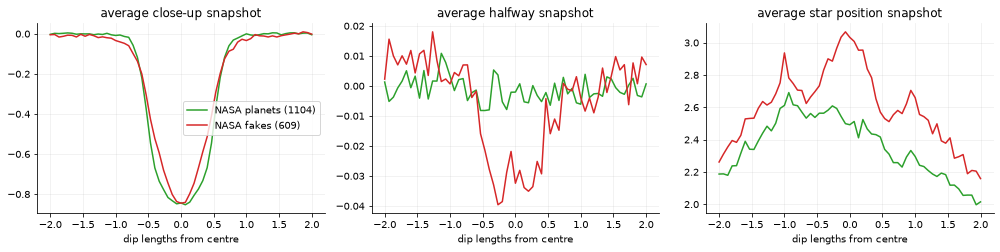

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for name, ax in zip(['local', 'secondary', 'centroid'], axes):
    for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        rows = hard.view_row[hard.y == yy].values
        ax.plot(x_local, npz[name][rows].mean(0), color=c, label=f'{lab} ({len(rows)})')
    ax.set(title=f'average {NAMES[name]} snapshot', xlabel='dip lengths from centre')
axes[0].legend()
plt.tight_layout(); plt.show()

On average, planets have a wider, flatter bottom (U) and fakes are more pointed (V); fakes show a small halfway dip and move more during the dip. These are averages: single planets and fakes overlap a lot.

<a id="ch7"></a>
# Chapter 7: The models, and how we grade them

**What you'll learn:** the two models (trees on the numbers; a neural network on pictures + numbers + pixel images), how a model learns, and the fair ways to grade it.

## Fair grading: never test on a star the model trained on

All dips of one star are similar. If a model trained on one dip of a star and was tested on another, it could just recognise the star. So the stars are split into **5 groups**; each group is scored by a model trained on the other 4. Every score in this chapter comes from a model that **never saw that star**.

In [24]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=m3.SEED)   # the pipeline's split
groups = []
for k, (tr, te) in enumerate(splitter.split(df, df.y, groups=df.tic)):
    assert not set(df.tic.iloc[tr]) & set(df.tic.iloc[te])
    groups.append({'group': k, 'test stars': df.tic.iloc[te].nunique(), 'test dips': len(te),
                   'planets in test': int(df.y.iloc[te].sum()), 'stars in both train and test': 0})
display(pd.DataFrame(groups).set_index('group'))

,test stars,test dips,planets in test,stars in both train and test
group,,,,
0,333,345,222,0
1,333,345,222,0
2,332,345,222,0
3,332,345,222,0
4,333,345,223,0


## Model 1: gradient-boosted trees on the 12 numbers

A **tree** is a chain of yes/no questions ("depth above 5,000 ppm?"). Boosting adds hundreds of small trees, each fixing the mistakes of the ones before. Here we retrain it live (`03_train_trees.py`'s own function) and check it reproduces the stored scores.

trained 2 x 5 tree models in 14 s


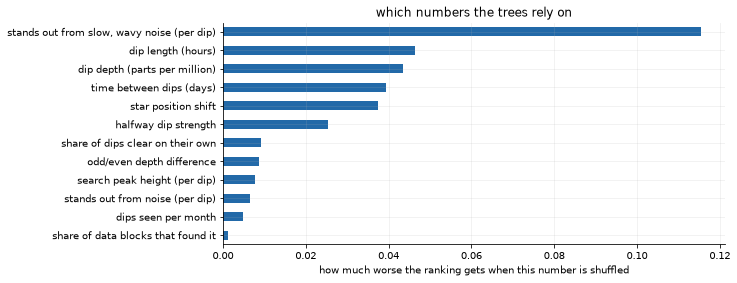

check: a model that only knows HOW MUCH data a star has: ROC AUC 0.79 (the real trees: 0.86; ROC AUC is explained below)


In [25]:
t0 = time.time()
tree_s, tree_folds, importances = m3.cross_validate(df, m3.DIP_FEATURES)
amount_s, _, _ = m3.cross_validate(df, m3.AMOUNT_FEATURES)
print(f'trained 2 x 5 tree models in {time.time() - t0:.0f} s')
assert (tree_folds == df.fold.values).all()               # same star groups as the stored shape-model run
stored = pd.read_csv(OUT_DIR / 'classifier_scores.csv')
same = df[['tic', 'signal']].assign(live=tree_s).merge(stored[['tic', 'signal', 'planet_score']])
assert len(same) == len(df) and np.allclose(same.live, same.planet_score, atol=1e-6)
df['tree_score'] = tree_s

fig, ax = plt.subplots(figsize=(9, 4))
pd.Series(importances, index=list(PLAIN.values())).sort_values().plot.barh(ax=ax, color=PAL[0])
ax.set(xlabel='how much worse the ranking gets when this number is shuffled', title='which numbers the trees rely on')
plt.show()
print(f"check: a model that only knows HOW MUCH data a star has: ROC AUC {roc_auc_score(df.y, amount_s):.2f} "
      f"(the real trees: {roc_auc_score(df.y, tree_s):.2f}; ROC AUC is explained below)")

The "how much data" check shows why the numbers are per dip: knowing only how many months a star was watched already predicts the answer somewhat, because NASA re-observes planet stars more. That's a shortcut we don't want the model to use.

## Model 2: the shape model (a small neural network)

**An everyday comparison.** A new fruit inspector is shown thousands of fruits, each labelled "ripe" or "unripe" by an expert. At first they guess. After every guess they are told the answer and adjust what they pay attention to. After many rounds they're good at it, even on new fruit. Our network is the inspector; the fruits are dips; the expert labels are NASA's verdicts; "what it pays attention to" is ~100,000 adjustable numbers (*weights*).

The training loop: (1) **guess** scores for a batch of 128 dips; (2) **compare** with NASA's answers; (3) compute a **penalty**, small when right and confident, large when confidently wrong; (4) **nudge** every weight to shrink the penalty; (5) **repeat**. One pass through all training dips is a **round**.

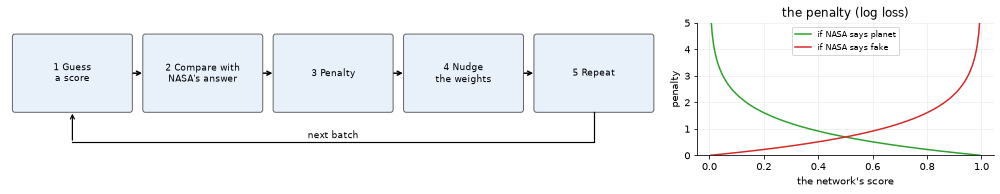

In [26]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 2.8), gridspec_kw={'width_ratios': [2.2, 1]})
flow(a1, ['1 Guess\na score', "2 Compare with\nNASA's answer", '3 Penalty', '4 Nudge\nthe weights', '5 Repeat'], y=0.62, h=0.55)
a1.plot([4.5, 4.5, 0.5], [0.33, 0.1, 0.1], color='k', lw=1.2)
a1.annotate('', xy=(0.5, 0.33), xytext=(0.5, 0.1), arrowprops=dict(arrowstyle='->', lw=1.2))
a1.text(2.5, 0.13, 'next batch', ha='center', fontsize=9)
a1.set_ylim(0, 1)
s = np.linspace(0.005, 0.995, 200)
a2.plot(s, -np.log(s), color='tab:green', label='if NASA says planet')
a2.plot(s, -np.log(1 - s), color='tab:red', label='if NASA says fake')
a2.set(xlabel="the network's score", ylabel='penalty', title='the penalty (log loss)', ylim=(0, 5))
a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Holding some stars aside.** A network can *memorise* its training dips instead of learning general rules. So 15% of the training stars are never used for nudging; after each round we check the penalty on them, and stop when it hasn't improved for 15 rounds, keeping the best version.

Now we train one network on CPU, on every star **except** group 0 and our four examples. (To keep it quick and simple, this one uses the pictures and numbers, not the pixel images of chapter 8; the stored production scores use all three.)

trained on 1170 dips, checked on 207 held-aside dips, 59 rounds, 14 s; 101,921 weights


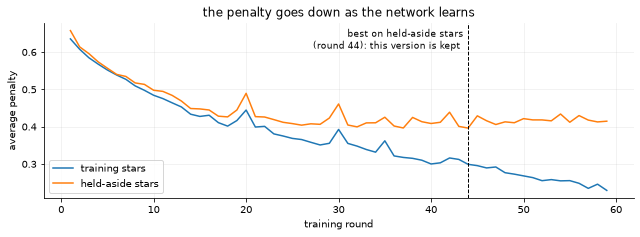

In [27]:
views = {k: np.clip(npz[k][df.view_row], -10, 10) for k in ['global'] + m6.LOCAL}
g = torch.as_tensor(views['global'][:, None])                   # whole orbit: 1 picture x 201 points
l = torch.as_tensor(np.stack([views[k] for k in m6.LOCAL], 1))  # close-ups: 5 pictures x 61 points
yt = torch.as_tensor(df.y.values.astype(np.float32))
train = np.flatnonzero((df.fold.values != 0) & ~df.tic.isin([r.tic for r in ex.values()]).values)
x = torch.as_tensor(m6.features(df, train))                     # 12 numbers (rescaled) + 12 'missing' flags
fit, val = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0)
                .split(train, groups=df.tic.values[train]))    # 15% of training stars held aside

torch.manual_seed(0)
untrained = m6.ShapeNet(x.shape[1]).eval()                      # same starting point as the trained one
history = []
t0 = time.time()
net = m6.train_one(g, l, x, yt, train[fit], train[val], seed=0, history=history).eval()
history = np.array(history)
best = history[:, 1].argmin()
print(f'trained on {len(fit)} dips, checked on {len(val)} held-aside dips, {len(history)} rounds, '
      f'{time.time() - t0:.0f} s; {sum(p.numel() for p in net.parameters()):,} weights')

fig, ax = plt.subplots(figsize=(9, 3.4))
rounds = np.arange(1, len(history) + 1)
ax.plot(rounds, history[:, 0], color='tab:blue', label='training stars')
ax.plot(rounds, history[:, 1], color='tab:orange', label='held-aside stars')
ax.axvline(best + 1, color='k', ls='--', lw=1)
ax.text(best + 0.5, 0.97, f'best on held-aside stars\n(round {best + 1}): this version is kept ', va='top', ha='right',
        fontsize=9, transform=ax.get_xaxis_transform())
ax.set(xlabel='training round', ylabel='average penalty', title='the penalty goes down as the network learns')
ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

Both penalties fall at first. Later the training stars keep improving while the held-aside stars level off: from there on the network is mostly memorising. So we keep the best round.

### Before and after training (unseen group-0 dips)

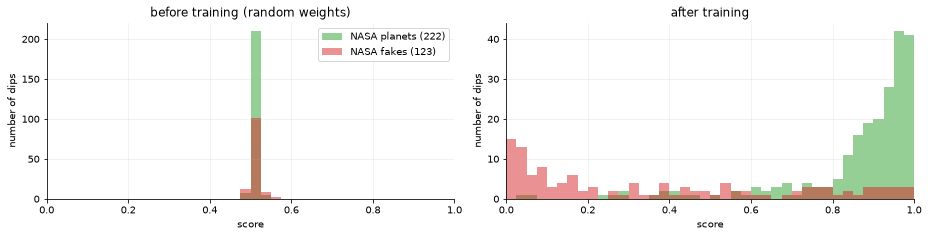

In [28]:
test = np.flatnonzero(df.fold.values == 0)
with torch.no_grad():
    before = torch.sigmoid(untrained(g[test], l[test], x[test])).numpy()
    after = torch.sigmoid(net(g[test], l[test], x[test])).numpy()
y_test = df.y.values[test]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, s, title in [(axes[0], before, 'before training (random weights)'), (axes[1], after, 'after training')]:
    for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
        ax.hist(s[y_test == yy], np.linspace(0, 1, 41), alpha=.5, color=c, label=f'{lab} ({(y_test == yy).sum()})')
    ax.set(title=title, xlabel='score', ylabel='number of dips', xlim=(0, 1))
axes[0].legend()
plt.tight_layout(); plt.show()
assert np.ptp(before) < 0.2 and roc_auc_score(y_test, after) > 0.8

Before training every dip gets about the same score. After training the planets pile up near 1; the fakes mostly score lower, but some still score high: the fakes that look most like planets.

### Grading, part 1: ranking quality (ROC AUC)

Pick one real planet and one fake at random. How often does the planet get the higher score? That fraction is the **ROC AUC**: 0.5 = coin flip, 1 = every planet above every fake. Below, lines join 40 random planet-fake pairs: green if the planet scored higher.

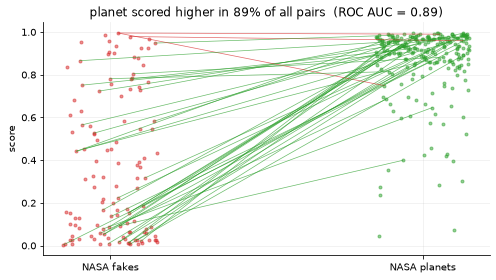

In [29]:
pl, fk = after[y_test == 1], after[y_test == 0]
pair_share = ((pl[:, None] > fk[None, :]).mean() + 0.5 * (pl[:, None] == fk[None, :]).mean())
auc = roc_auc_score(y_test, after)
assert np.isclose(pair_share, auc)

rng = np.random.default_rng(0)
xp, xf = 1 + rng.uniform(-.15, .15, len(pl)), rng.uniform(-.15, .15, len(fk))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xf, fk, '.', color='tab:red', alpha=.5); ax.plot(xp, pl, '.', color='tab:green', alpha=.5)
for i, j in zip(rng.integers(len(pl), size=40), rng.integers(len(fk), size=40)):
    ax.plot([xf[j], xp[i]], [fk[j], pl[i]], color='tab:green' if pl[i] > fk[j] else 'tab:red', lw=.7, alpha=.7)
ax.set(xticks=[0, 1], xticklabels=['NASA fakes', 'NASA planets'], ylabel='score',
       title=f'planet scored higher in {pair_share:.0%} of all pairs  (ROC AUC = {auc:.2f})')
plt.tight_layout(); plt.show()

### Grading, part 2: planets caught at the old rules' false-alarm rate

Before any model, the project used fixed rules (SDE ≥ 7, pink SNR ≥ 7.1, at least 2 dips, no warning flags). They let through a certain share of fakes. Fair comparison: set the model's cutoff to let through **the same share of fakes**, and count the planets each catches.

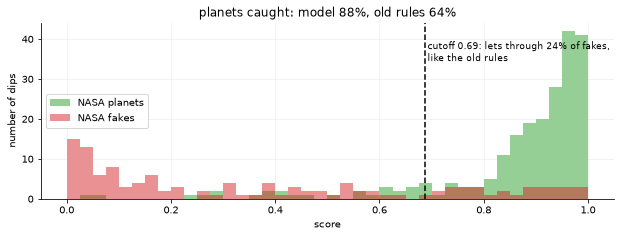

In [30]:
mask = np.zeros(len(df), bool); mask[test] = True
s_all = np.zeros(len(df)); s_all[test] = after
stats, _ = m3.fold_stats(df, s_all, np.zeros(len(df), int), mask)
rules = df.rules_pass.values[test]
fake_rate = rules[y_test == 0].mean()
cut = np.quantile(fk, 1 - fake_rate)
assert np.isclose((pl > cut).mean(), stats.model_planets_caught)

fig, ax = plt.subplots(figsize=(9, 3.4))
for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
    ax.hist(after[y_test == yy], np.linspace(0, 1, 41), alpha=.5, color=c, label=lab)
ax.axvline(cut, color='k', ls='--')
ax.text(cut, ax.get_ylim()[1] * .9, f' cutoff {cut:.2f}: lets through {fake_rate:.0%} of fakes,\n like the old rules', fontsize=9, va='top')
ax.set(xlabel='score', ylabel='number of dips', title=f'planets caught: model {stats.model_planets_caught:.0%}, '
       f'old rules {stats.rules_planets_caught:.0%}')
ax.legend(loc='center left')
plt.tight_layout(); plt.show()

### Grading, part 3: plain accuracy, and why it misleads

Call everything above 0.5 a planet, and count right and wrong answers.

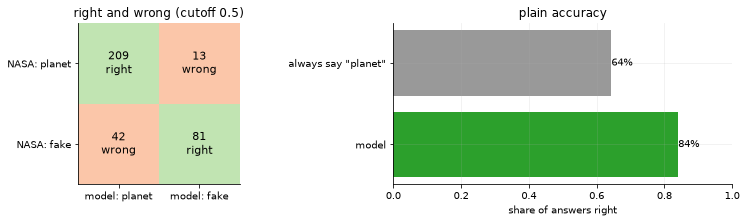

In [31]:
called = after > 0.5
grid = pd.DataFrame([[(called & (y_test == 1)).sum(), (~called & (y_test == 1)).sum()],
                     [(called & (y_test == 0)).sum(), (~called & (y_test == 0)).sum()]],
                    index=['NASA: planet', 'NASA: fake'], columns=['model: planet', 'model: fake'])
accuracy = (called == y_test).mean()
always = (y_test == 1).mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
a1.imshow([[1, 0], [0, 1]], cmap='RdYlGn', vmin=-.5, vmax=1.5, alpha=.5)
for i in range(2):
    for j in range(2):
        a1.text(j, i, f"{grid.iat[i, j]}\n{'right' if i == j else 'wrong'}", ha='center', va='center', fontsize=11)
a1.set(xticks=[0, 1], xticklabels=grid.columns, yticks=[0, 1], yticklabels=grid.index, title='right and wrong (cutoff 0.5)')
a1.grid(False)
bars = a2.barh(['model', 'always say "planet"'], [accuracy, always], color=['tab:green', '0.6'])
a2.bar_label(bars, labels=[f'{v:.0%}' for v in [accuracy, always]])
a2.set(xlim=(0, 1), xlabel='share of answers right', title='plain accuracy')
plt.tight_layout(); plt.show()
assert 0.55 < df.y.mean() < 0.7

The bottom-left cell is the costly mistake: fakes called planets. About two thirds of the dips are planets, so a "model" that always says "planet" is already right ~2/3 of the time while catching zero fakes. Ranking quality (part 1) and planets caught at a fixed false-alarm rate (part 2) don't have this problem, so those are the numbers we trust.

## Pictures, numbers, or both?

The full experiment, from the stored results (`shape_scores.csv`, made on a GPU): all 5 groups, each scored by 5 networks that never saw it, averaged. Plus the trees above and the old rules. Bars: average over the 5 groups; whiskers: spread over the groups.

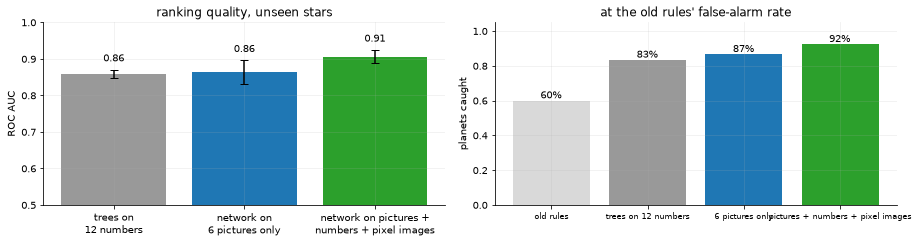

In [32]:
results = {}
for col, name in [('tree_score', 'trees on\n12 numbers'), ('views', 'network on\n6 pictures only'),
                  ('views_features', 'network on pictures +\nnumbers + pixel images')]:
    results[name] = m3.fold_stats(df, df[col].values, df.fold.values)
mean = pd.DataFrame({n: m for n, (m, _) in results.items()}).T
std = pd.DataFrame({n: s for n, (_, s) in results.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
bars = axes[0].bar(mean.index, mean.roc_auc, yerr=std.roc_auc, color=['0.6', 'tab:blue', 'tab:green'], capsize=4)
axes[0].bar_label(bars, fmt='%.2f', padding=6); axes[0].set(ylim=(0.5, 1), ylabel='ROC AUC', title='ranking quality, unseen stars')
caught = pd.concat([pd.Series({'old rules': mean.rules_planets_caught.iloc[0]}), mean.model_planets_caught])
bars = axes[1].bar(caught.index.str.replace('\n', ' ').str.replace('network on ', ''), caught, color=['0.85', '0.6', 'tab:blue', 'tab:green'])
axes[1].bar_label(bars, labels=[f'{v:.0%}' for v in caught]); axes[1].set(ylim=(0, 1.05), ylabel='planets caught', title="at the old rules' false-alarm rate")
axes[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
assert mean.roc_auc.iloc[2] > mean.roc_auc.iloc[:2].max() and (mean.model_planets_caught > mean.rules_planets_caught).all()

Pictures alone and numbers alone are about equally good; together (with the pixel images) they rank best, and every model catches far more planets than the old rules at the same false-alarm rate. The models also beat the rules within groups of stars with the same amount of data, so it's not just the "more data" shortcut:

In [33]:
h = df.assign(score=df.tree_score)
rows = []
for months, grp in h.groupby(pd.cut(h.sectors, [0, 1, 2, 4, 8], labels=['1', '2', '3-4', '5-8']), observed=True):
    fake_rate = grp.rules_pass[grp.y == 0].mean()
    cut = np.quantile(grp.score[grp.y == 0], 1 - fake_rate)
    rows.append({'months of data': months, 'dips': len(grp), 'rules catch': grp.rules_pass[grp.y == 1].mean(),
                 'trees catch (same false-alarm rate)': (grp.score[grp.y == 1] > cut).mean()})
within = pd.DataFrame(rows).set_index('months of data')
display(within.style.format({'rules catch': '{:.0%}', 'trees catch (same false-alarm rate)': '{:.0%}'}))
assert (within['trees catch (same false-alarm rate)'] > within['rules catch']).all()

,dips,rules catch,trees catch (same false-alarm rate)
months of data,,,
1,232,64%,81%
2,527,55%,85%
3-4,604,62%,84%
5-8,362,62%,81%


## A look inside the network

The model is a *convolutional neural network* (CNN): instead of looking at all 61 points at once, it slides many small **pattern detectors** (5 points wide) along each picture and notes where each one matches. One reader takes the whole-orbit picture, another the five close-ups stacked together; later layers combine small patterns into bigger ones; finally everything is joined with the 12 numbers into one score.

Below: the weights of the 4 first-layer detectors that rely most on the close-up picture. Simple shapes; nothing here "knows" about planets.

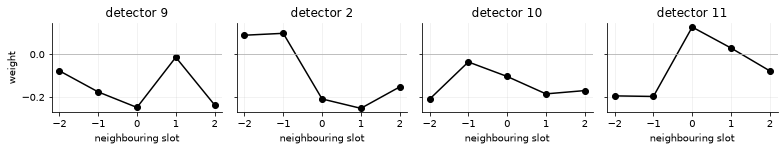

In [34]:
conv1 = net.loc[0]                              # first layer of the close-up reader
Wc = conv1.weight.detach()[:, 0]                # weights applied to the close-up picture: 16 x 5
pick = torch.argsort(Wc.norm(dim=1), descending=True)[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(11, 2.2), sharey=True)
for ax, i in zip(axes, pick):
    ax.plot(range(-2, 3), Wc[i], 'o-', color='k')
    ax.axhline(0, color='0.7', lw=.8)
    ax.set(title=f'detector {i}', xticks=range(-2, 3), xlabel='neighbouring slot')
axes[0].set_ylabel('weight')
plt.tight_layout(); plt.show()

### Where on the dip each detector lights up

Slide each detector along the close-up of A (planet) and B (two stars). The response is how well the 5 points around each slot match (negative matches set to 0).

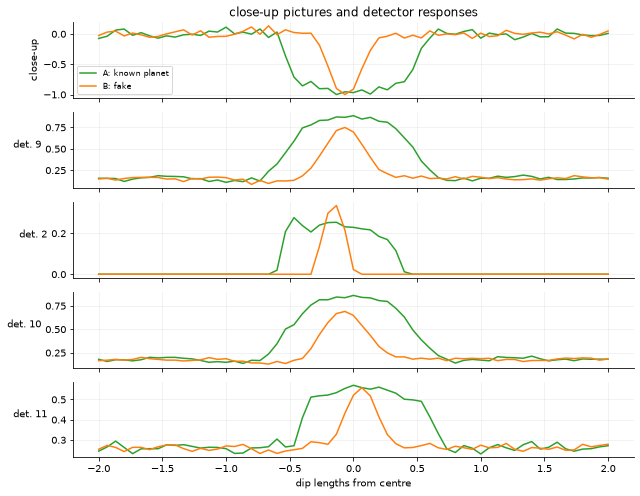

In [35]:
def response(k):
    s = torch.as_tensor(snap[k]['local'], dtype=torch.float32)[None, None]
    return torch.relu(torch.nn.functional.conv1d(s, Wc[:, None], conv1.bias.detach(), padding=2))[0]

fig, axes = plt.subplots(len(pick) + 1, 1, figsize=(9, 7), sharex=True)
for k in ['A', 'B']:
    axes[0].plot(x_local, snap[k]['local'], color=COLORS[k], label=f'{k}: {VERDICT[ex[k].label]}')
    r = response(k)
    for ax, i in zip(axes[1:], pick):
        ax.plot(x_local, r[i], color=COLORS[k])
        ax.set_ylabel(f'det. {i}', rotation=0, ha='right')
axes[0].set(title='close-up pictures and detector responses', ylabel='close-up')
axes[0].legend(loc='lower left', fontsize=8)
axes[-1].set_xlabel('dip lengths from centre')
plt.tight_layout(); plt.show()

Most detectors fire where the picture is low, inside the dip: a **wide plateau** for the planet (the U's flat floor), a **narrow spike** for the two-star pair. So even the first layer turns the shape into "how wide and flat is the low part".

### What each input contributes

Score each example three ways: as is; with its pictures swapped for the **average pictures**; and with its numbers swapped for **average values**. What does its own shape, or its own numbers, add?

In [36]:
g_avg, l_avg = g[train].mean(0, keepdim=True), l[train].mean(0, keepdim=True)
x_avg = torch.zeros(1, x.shape[1])   # numbers were rescaled on the training dips, so 0 = average

def score(i, own_pictures=True, own_numbers=True):
    with torch.no_grad():
        return torch.sigmoid(net(g[i] if own_pictures else g_avg, l[i] if own_pictures else l_avg,
                                 x[i] if own_numbers else x_avg)).item()

rows = {}
for k, r in ex.items():
    i = [df.index[(df.tic == r.tic) & (df.signal == r.signal)][0]]
    rows[f'{k} ({VERDICT[r.label]})'] = {'full score': score(i),
                                         'average pictures instead': score(i, own_pictures=False),
                                         'average numbers instead': score(i, own_numbers=False)}
contrib = pd.DataFrame(rows).T
display(contrib.round(4))
own_pics, own_nums = contrib['average numbers instead'], contrib['average pictures instead']
assert own_nums.iloc[0] < 0.5 < own_pics.iloc[0]                 # A: its pictures carry it
assert (own_nums.iloc[1:] < own_pics.iloc[1:]).all()             # fakes: their numbers do more

,full score,average pictures instead,average numbers instead
A (known planet),0.9714,0.1775,0.9906
B (fake),0.0099,0.0146,0.3877
C (fake),0.0068,0.0085,0.4581
D (fake),0.0053,0.0275,0.1242


- **A (planet)**: with average pictures its score drops below 0.5; with average numbers it stays high. A's *shape* convinces the network (the trees, which see only numbers, called A a fake).
- **B, C, D (fakes)**: their own numbers (halfway dip, position shift, odd/even) push the score down more than their pictures do.

So pictures rescue planets whose numbers look odd, and numbers catch fakes whose shape looks fine. (One network, one random start; the stored scores average 5 per group, so values differ a little.)

<a id="ch8"></a>
# Chapter 8: Pixel images: which star dimmed?

**What you'll learn:** what a difference image is, how it shows whether the dip happened on our star or on a neighbour, and how much it helps the model.

A light curve adds up the light of a small patch of camera pixels around our star. If a **neighbouring** star in that patch dims, our light curve dips too: a classic fake. TESS also saves the raw pixel pictures (*target pixel files*), so we can look.

A **difference image** = the average picture just **outside** the dips minus the average picture **during** the dips. Pixels that lost light during the dips come out bright. If the bright spot sits on our star, it's our star dimming; if it sits elsewhere, it's a neighbour. Each image is a small 11 × 11 pixel crop centred on our star. Step 5 (`05_build_pixel_views.py`) built them; here we read the committed file.

channels in the file: ['diff_over_peak', 'diff_snr_log1p', 'out_over_max', 'target_marker']


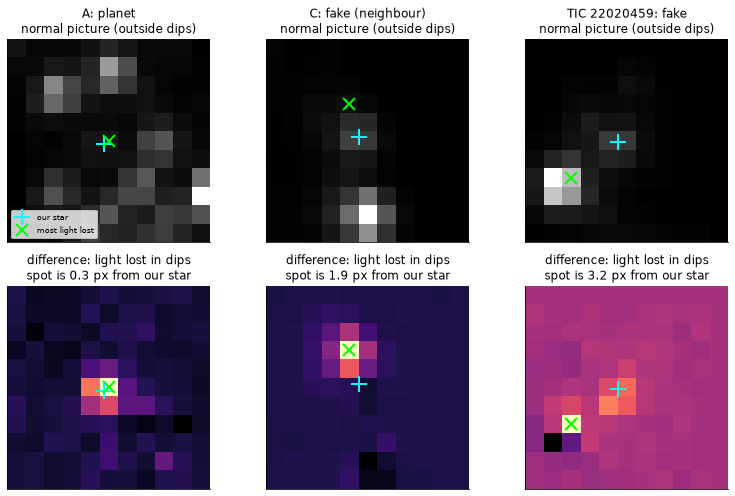

In [37]:
print('channels in the file:', PIX_META['channels'])
OFF = PIX_META['off_target_px']                 # farther than this from the target counts as "off target"
d8 = df.merge(pd.DataFrame({'tic': pix['tic'], 'signal': pix['signal'], 'ok': pix['ok'], 'offset_px': pix['offset_px']}),
              on=['tic', 'signal'])
assert len(d8) == len(df) and d8.ok.all()

far = d8[(d8.y == 0) & (d8.offset_px.between(2.5, 4))].sort_values('tic').iloc[0]   # a fake well off target
cases = [('A: planet', ex['A']), ('C: fake (neighbour)', ex['C']), (f'TIC {far.tic}: fake', far)]
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for j, (title, r) in enumerate(cases):
    img = pix['x'][r.pix_row]
    marker = img[3]                                      # a soft spot at the target's exact position
    yy, xx = np.mgrid[:marker.shape[0], :marker.shape[1]]
    ty, tx = (marker * yy).sum() / marker.sum(), (marker * xx).sum() / marker.sum()
    by, bx = np.unravel_index(np.argmax(img[0]), img[0].shape)   # pixel that lost the most light
    offset = pix['offset_px'][r.pix_row]
    assert abs(np.hypot(by - ty, bx - tx) - offset) < 0.5
    for i, (ch, name, cmap) in enumerate([(2, 'normal picture (outside dips)', 'gray'),
                                          (0, 'difference: light lost in dips', 'magma')]):
        ax = axes[i, j]
        ax.imshow(img[ch], cmap=cmap, origin='lower')
        ax.plot(tx, ty, '+', color='cyan', ms=16, mew=2, label='our star')
        ax.plot(bx, by, 'x', color='lime', ms=12, mew=2, label='most light lost')
        ax.set(title=f'{title}\n{name}' if i == 0 else f'{name}\nspot is {offset:.1f} px from our star', xticks=[], yticks=[])
        ax.grid(False)
axes[0, 0].legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()
assert ex['A'].pix_row is not None and pix['offset_px'][ex['A'].pix_row] < OFF < pix['offset_px'][ex['C'].pix_row]

For planet A the light was lost right on our star (cyan +). For fake C, and even more for the third fake, the most light was lost a pixel or more away: a neighbour dimmed. (C is the fake whose *star position* moved in chapter 5; the pixel image shows the same thing more directly.)

## Over all dips: distance from our star to the spot

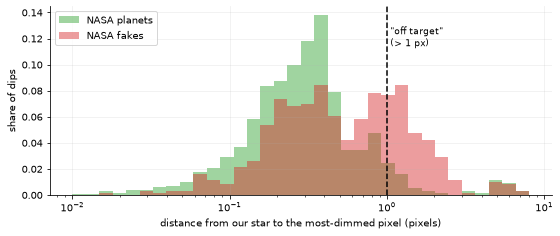

,share off target
y,
NASA fakes,28%
NASA planets,7%


In [38]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.geomspace(0.01, 8, 35)
for yy, lab, c in [(1, 'NASA planets', 'tab:green'), (0, 'NASA fakes', 'tab:red')]:
    v = d8.offset_px[d8.y == yy]
    ax.hist(v, bins, weights=np.full(len(v), 1 / len(v)), alpha=.45, color=c, label=lab)
ax.axvline(OFF, color='k', ls='--')
ax.text(OFF * 1.05, ax.get_ylim()[1] * .9, f'"off target"\n(> {OFF:g} px)', fontsize=9, va='top')
ax.set(xscale='log', xlabel='distance from our star to the most-dimmed pixel (pixels)', ylabel='share of dips')
ax.legend(loc='upper left'); plt.show()
off_share = d8.groupby('y').offset_px.apply(lambda v: (v > OFF).mean()).rename({0: 'NASA fakes', 1: 'NASA planets'})
display(off_share.rename('share off target').to_frame().style.format('{:.0%}'))
assert off_share['NASA fakes'] > 3 * off_share['NASA planets']

Fakes are off target several times as often as planets. Not every fake is off target (two-star pairs right on our star look "on target"), and a few planets come out off target from noise, so the pixel image is one more clue, not a verdict.

## Does it help the model?

The stored shape-model scores include the pixel images. The run *without* them was done on the GPU and isn't in a committed file, so its numbers are **from the README**: same folds and seeds, ROC AUC 0.90 ± 0.02 without vs 0.91 ± 0.02 with (better in all 5 folds, by +0.004 to +0.021), and off-target fakes scored above 0.5 **12%** of the time without pixel images.

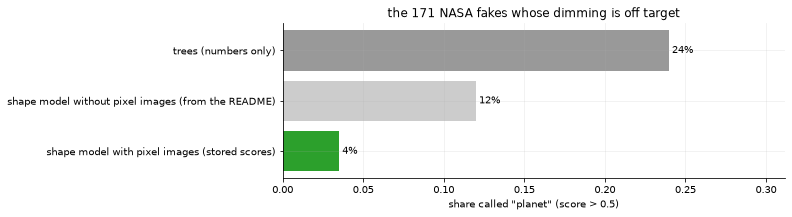

shape model with pixel images (stored): ROC AUC 0.91


In [39]:
offt = d8[(d8.y == 0) & (d8.offset_px > OFF)]
called = pd.Series({'trees (numbers only)': (offt.tree_score > .5).mean(),
                    'shape model without pixel images (from the README)': 0.12,
                    'shape model with pixel images (stored scores)': (offt.views_features > .5).mean()})
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(called.index, called, color=['0.6', '0.8', 'tab:green'])
ax.bar_label(bars, labels=[f'{v:.0%}' for v in called], padding=3)
ax.set(xlabel='share called "planet" (score > 0.5)', title=f'the {len(offt)} NASA fakes whose dimming is off target', xlim=(0, max(called) * 1.3))
ax.invert_yaxis(); plt.show()
with_pix, _ = m3.fold_stats(df, df.views_features.values, df.fold.values)
print(f'shape model with pixel images (stored): ROC AUC {with_pix.roc_auc:.2f}')
assert len(offt) == 171 and called.iloc[2] < 0.05 and round(with_pix.roc_auc, 2) == 0.91   # the README's numbers

The gain in overall ranking is small (within the spread between folds), but it is exactly where expected: off-target fakes are now rarely called planets.

<a id="ch9"></a>
# Chapter 9: "Nothing here" stars

**What you'll learn:** why a model trained only on NASA's checked dips gets fooled by plain junk, and how adding random stars with no TOI fixes that.

NASA only checks dips that already looked promising. So both our "planets" and our "fakes" are dips that looked like planets at first glance. A model trained on them never sees **plain junk**: the noise bumps our search also finds on ordinary stars. Yet the stars we rank at the end produce plenty of such junk.

So dataset_v2 adds 1,000 **random stars with no TOI** (label **NT**). Whatever our search finds on them is almost certainly not a planet. With `--nt` they train as fakes; they are **never** used for grading (they'd make the task look too easy).

Below we train the trees on dataset_v2 live, twice: without and with the NT dips.

load: dropped 18 rows ({'FP': 13, 'FA': 4, 'KP': 1}) of 18 stars with no light curve of their own


2464 NT dips from 997 random stars; trained in 17 s


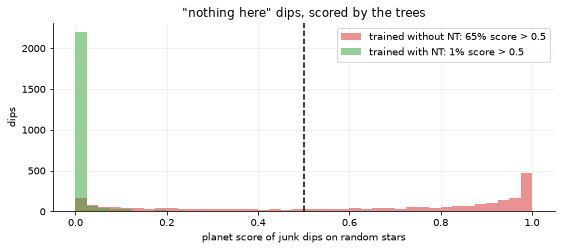

In [40]:
t0 = time.time()
v2 = m3.load('dataset_v2', nt=True).reset_index(drop=True)
is_nt = v2.label.eq('NT').values
nasa = v2[~is_nt].reset_index(drop=True)
s_nasa, f_nasa, _ = m3.cross_validate(nasa, m3.DIP_FEATURES)     # without NT (NT stars unseen)
s_with, f_with, _ = m3.cross_validate(v2, m3.DIP_FEATURES)       # with NT as fakes (each NT dip scored unseen)
# Score the NT dips with a model that never saw any NT star: same settings as m3.cross_validate, all NASA dips.
no_nt = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=m3.SEED)
nt_before = no_nt.fit(nasa[m3.DIP_FEATURES], nasa.y).predict_proba(v2.loc[is_nt, m3.DIP_FEATURES])[:, 1]
nt_after = s_with[is_nt]
print(f'{is_nt.sum()} NT dips from {v2.tic[is_nt].nunique()} random stars; trained in {time.time() - t0:.0f} s')

fig, ax = plt.subplots(figsize=(9, 3.4))
for s, lab, c in [(nt_before, 'trained without NT', 'tab:red'), (nt_after, 'trained with NT', 'tab:green')]:
    ax.hist(s, np.linspace(0, 1, 41), alpha=.5, color=c, label=f'{lab}: {(s > .5).mean():.0%} score > 0.5')
ax.axvline(.5, color='k', ls='--')
ax.set(xlabel='planet score of junk dips on random stars', ylabel='dips', title='"nothing here" dips, scored by the trees')
ax.legend(); plt.show()
assert (nt_before > .5).mean() > 0.3 and (nt_after > .5).mean() < 0.1

Without NT, the model calls a large share of plain junk a planet: it never learned that "nothing" is an option. With NT, almost none. **(From the README:** for the shape model the same change is over half → ~1%.)

## The cost on the hard task

Does learning about junk make the model worse at telling NASA's planets from NASA's fakes? Graded on NASA-labelled dips only:

In [41]:
cost = pd.DataFrame({'without NT': m3.fold_stats(nasa, s_nasa, f_nasa)[0],
                     'with NT': m3.fold_stats(v2, s_with, f_with, v2.hard.values)[0]}).loc[['roc_auc', 'model_planets_caught']]
cost.index = ['ROC AUC', "planets caught at the rules' false-alarm rate"]
display(cost.round(3))
assert 0 <= cost.loc['ROC AUC', 'without NT'] - cost.loc['ROC AUC', 'with NT'] < 0.05

,without NT,with NT
ROC AUC,0.878,0.851
planets caught at the rules' false-alarm rate,0.861,0.828


A small cost, within the spread between folds **(README:** ~0.01 for the shape model, ~0.03 for the trees). Worth it: the final ranked list is mostly made of exactly this kind of junk, which is why `07 score` trains with `--nt`.

<a id="ch10"></a>
# Chapter 10: The "unsure" flag

**What you'll learn:** how training 5 copies of the network and comparing their scores flags dips the model is unsure about, and how to use the flag in the ranked list.

The shape model is trained **5 times** per group, from different random starts, and the final score is their average. If the 5 copies disagree a lot on a dip, the model is unsure. The **spread** (standard deviation of the 5 scores) is saved as `shape_score_spread`.

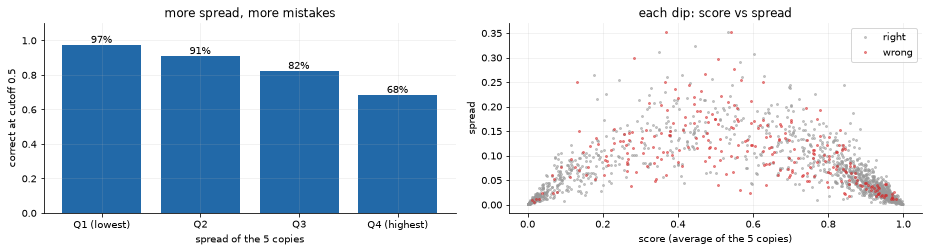

,dips,correct,score_near_half
spread quartile,,,
Q1 (lowest),432,97%,0%
Q2,431,91%,2%
Q3,431,82%,15%
Q4 (highest),431,68%,59%


In [42]:
d10 = df.assign(wrong=(df.views_features > .5) != (df.y == 1))
d10['spread quartile'] = pd.qcut(d10.shape_score_spread, 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
q = d10.groupby('spread quartile', observed=True).agg(
    dips=('y', 'size'), correct=('wrong', lambda w: 1 - w.mean()),
    score_near_half=('views_features', lambda s: (abs(s - .5) < .2).mean()))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
bars = axes[0].bar(q.index.astype(str), q.correct, color=PAL[0])
axes[0].bar_label(bars, labels=[f'{v:.0%}' for v in q.correct])
axes[0].set(ylim=(0, 1.1), ylabel='correct at cutoff 0.5', xlabel='spread of the 5 copies', title='more spread, more mistakes')
for w, lab, c in [(False, 'right', '0.6'), (True, 'wrong', 'tab:red')]:
    s = d10[d10.wrong == w]
    axes[1].plot(s.views_features, s.shape_score_spread, '.', ms=4, alpha=.5, color=c, label=lab)
axes[1].set(xlabel='score (average of the 5 copies)', ylabel='spread', title='each dip: score vs spread')
axes[1].legend(); plt.tight_layout(); plt.show()
display(q.style.format({'correct': '{:.0%}', 'score_near_half': '{:.0%}'}))
assert q.correct.is_monotonic_decreasing

High spread goes with scores near 0.5 (the right picture's hump): mostly, the flag repeats what a middling score already says. Which finds the wrong calls better?

In [43]:
find = pd.Series({'closeness of the score to 0.5': roc_auc_score(d10.wrong, -abs(d10.views_features - .5)),
                  'spread of the 5 copies': roc_auc_score(d10.wrong, d10.shape_score_spread)})
display(find.rename('how well it finds wrong calls (ROC AUC)').to_frame().round(2))
confident = d10[abs(d10.views_features - .5) > .3]                  # score below 0.2 or above 0.8
top_q = confident.shape_score_spread > d10.shape_score_spread.quantile(.75)
conf = confident.groupby(top_q).wrong.agg(['size', 'mean']).rename(index={False: 'spread Q1-Q3', True: 'spread Q4'})
conf.columns = ['confident dips', 'share wrong']
display(conf.style.format({'share wrong': '{:.0%}'}))
assert find.iloc[0] >= find.iloc[1] and conf.loc['spread Q4', 'share wrong'] > 1.5 * conf.loc['spread Q1-Q3', 'share wrong']

,how well it finds wrong calls (ROC AUC)
closeness of the score to 0.5,0.78
spread of the 5 copies,0.74


,confident dips,share wrong
shape_score_spread,,
spread Q1-Q3,1145,6%
spread Q4,66,24%


The score's closeness to 0.5 finds wrong calls a bit better than the spread. But among **confident-looking** scores (below 0.2 or above 0.8), high-spread dips are wrong over twice as often: the flag catches some mistakes the score alone hides.

## Using it in the ranked list

`candidate_ranking.csv` has `shape_score_spread` next to `shape_score`. Read it as: a high score with low spread is a strong candidate; a high score with high spread deserves a second look before anyone spends telescope time on it. In practice the very top of the list is almost never flagged; the flag matters most in the middle of the list. (That model was trained on dataset_v2 with NT, so compare spreads within the list, not with the numbers above.)

In [44]:
r = ranking.assign(unsure=ranking.shape_score_spread > ranking.shape_score_spread.quantile(.75))
bands = pd.cut(r.shape_score, [0, .2, .5, .8, .9, 1], include_lowest=True)
share = r.groupby(bands, observed=True).unsure.agg(['size', 'mean'])
share.columns = ['ranked dips', 'share flagged unsure (top quarter of spread)']
display(share.style.format({'share flagged unsure (top quarter of spread)': '{:.0%}'}))
print('planet-leaning (score > 0.5) but unsure, highest scores first:')
display(r[(r.shape_score > .5) & r.unsure].sort_values('shape_score', ascending=False)
        [['tic', 'toi', 'period', 'depth_ppm', 'shape_score', 'shape_score_spread']].head(5).round(3))
assert share.iloc[-1, 1] < share.iloc[1:3, 1].min()   # the very top scores are rarely unsure

,ranked dips,share flagged unsure (top quarter of spread)
shape_score,,
"(-0.001, 0.2]",391,4%
"(0.2, 0.5]",615,57%
"(0.5, 0.8]",1369,35%
"(0.8, 0.9]",664,1%
"(0.9, 1.0]",357,0%


planet-leaning (score > 0.5) but unsure, highest scores first:


,tic,toi,period,depth_ppm,shape_score,shape_score_spread
826,71221700,4869.01,3.098,2205.452,0.830,0.161
945,452658846,3567.01,1.997,8131.584,0.811,0.175
966,9701368,5774.01,5.406,22582.231,0.808,0.167
1019,58798731,5303.01,9.810,4430.214,0.800,0.188
1025,138329479,4147.01,2.375,9159.405,0.799,0.181


<a id="ch11"></a>
# Chapter 11: The wrong-star fix

**What you'll learn:** how a search by sky position quietly downloaded a neighbour's light curve for some stars, how many stars it hit, and why we dropped them.

We find a star's files with `lightkurve.search_lightcurve("TIC <number>")`. That is a **cone search**: it looks up the star's position and returns every file within a small circle around it. If our star has no 2-minute data of its own, it can return a *neighbour's* files instead, and older runs of step 2 used them as if they were ours.

Here is one live search (a few seconds, nothing downloaded) for a star with no files of its own:

In [45]:
TIC_WRONG = 1100766816
assert not stars['dataset'].set_index('tic').has_own_lc.astype(bool)[TIC_WRONG]
try:
    found = lk.search_lightcurve(f'TIC {TIC_WRONG}', author='SPOC', exptime=120)
except Exception as err:   # MAST unreachable: show the reason, keep going
    found = None
    print('MAST search unavailable right now:', err)
if found is not None:
    hits = found.table.to_pandas()[['target_name', 'mission', 'distance']]
    hits['file is our star?'] = [f'{TIC_WRONG:016d}' in u.split('/')[-1] for u in found.table['dataURI']]
    display(hits)
    print(f'asked for TIC {TIC_WRONG}; got files of TIC {sorted(set(hits.target_name))}')
    assert not hits['file is our star?'].any()

,target_name,mission,distance,file is our star?
0,445884778,TESS Sector 51,0.0,False


asked for TIC 1100766816; got files of TIC ['445884778']


Every file returned belongs to a different TIC number (`target_name`). The `distance` column shows how far that star's catalogued position is from ours; when it is 0 the two catalogue entries sit on the same point of sky (likely two entries for one blended source), so a position search can't tell them apart. Either way, the light curve is not the star NASA's verdict is about.

**The fix** (`02_build_dataset.py`): keep only files whose name contains our star's own TIC number; stars with none are marked `has_own_lc = False`, and `m3.load()` drops their dips.

,stars,without their own light curve
dataset,2454,18
dataset_v2,3454,18
candidates,5143,22


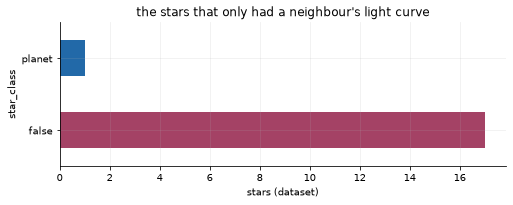

In [46]:
affected = pd.DataFrame({n: {'stars': len(stars[n]), 'without their own light curve': int((~stars[n].has_own_lc.astype(bool)).sum())}
                         for n in SETS}).T
display(affected)
bad = stars['dataset'][~stars['dataset'].has_own_lc.astype(bool)]
fig, ax = plt.subplots(figsize=(8, 2.6))
bad.star_class.value_counts().plot.barh(ax=ax, color=[PAL[3], PAL[0]])
ax.set(xlabel='stars (dataset)', title='the stars that only had a neighbour\'s light curve')
plt.show()
assert (bad.star_class == 'false').sum() == 17 and len(bad) == 18   # the README's 17 of 18

Only 18 of ~2,400 training stars were hit, but 17 of them were **fake** stars. A model could learn "this light curve doesn't really fit this star → fake", a shortcut that says nothing about planets. And the measurements describe the wrong star anyway. So they are dropped from training and grading; the 22 hit candidates are dropped from the ranked list.

<a id="ch12"></a>
# Chapter 12: Tried and dropped

**What you'll learn:** two ideas that sounded good but didn't help, and the likely reasons.

These were tested on the GPU; the runs aren't in committed files, so the numbers are from the experiment notes.

| idea | what it was | result | likely reason |
|---|---|---|---|
| each-dip snapshot | besides the stacked dip, give the network each single dip side by side (16 slots) | **worse in all 5 folds**: ROC AUC 0.90 → 0.85 | each slot holds a different dip for every star, so slot 3 means nothing in particular; too few examples to learn that from |
| synthetic data, round 1 | add made-up fake planets and made-up two-star pairs to training | **no gain**; paused | the made-up star pairs were far deeper than NASA's real fakes (too easy to be useful), and too few made-up planets were found by the search |

Both are kept in git history, not in the pipeline. The synthetic idea may come back with realistic settings (chapter 13).

<a id="ch13"></a>
# Chapter 13: Recap and what's next

**What you'll learn:** the whole pipeline in a few lines.

1. **Data**: TESS light curves (brightness every 2 minutes, a sector at a time) for the benchmark, the training stars, random "nothing here" stars and NASA's undecided candidates (ch. 1).
2. **Clean**: divide out slow drifts, average to 10 minutes (ch. 2).
3. **Search**: TLS finds the period where dips line up best (SDE ≥ 7), refits with the dips hidden from the smoothing, then hides them and searches again for a second signal (ch. 2).
4. **Benchmark**: on 100 stars it finds 44 of 60 known planet hosts (ch. 3).
5. **Labels**: a dip gets NASA's verdict only if its period matches a TOI; unmatched dips are left out (ch. 4).
6. **Numbers**: 12 measurements per dip, per dip where data amount would otherwise leak in (ch. 5).
7. **Pictures**: 6 folded snapshots, shape only (ch. 6); **pixel images**: which star dimmed (ch. 8).
8. **Models**: trees on the numbers; a small CNN on pictures + numbers + pixel images, 5 copies per group (ch. 7).
9. **Grading** on unseen stars, by ROC AUC and planets caught at the old rules' false-alarm rate, never plain accuracy (ch. 7).
10. **Junk**: random "nothing here" stars teach the model that "nothing" is an option (ch. 9).
11. **Unsure flag**: the spread of the 5 copies marks scores to double-check (ch. 10).
12. **Hygiene**: only a star's own light curve is used (ch. 11).

**What's next**

- Pixel images made the ranked list agree *less* with NASA's ExoMiner++ model (from the README: Spearman correlation 0.55 → 0.42, same call at 0.5 for 75% → 73% of dips). Find out which dips changed and who is right.
- Resume synthetic training data with realistic settings: made-up two-star pairs as shallow as NASA's real fakes, and enough made-up planets that the search actually recovers.

In [47]:
print(f'notebook ran in {time.time() - START:.0f} s')

notebook ran in 137 s
